In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from scipy.signal import find_peaks, peak_widths, savgol_filter
import pandas as pd
import h5py
from typing import Literal
import struct

plt.rcParams["figure.dpi"] = 500

In [3]:
def plot_with_peaks(
    data,
    n_bins,
    prominence=None,
    xlabel="",
    title="",
    xlims=None,
    savgol_window=None,
    savgol_strength=1.0,
    clip_counts=None,
    stacked=False,
    legend=None,
    bin_range=None,
    text_size=5,
):
    if not stacked:
        signals = [data]
    else:
        signals = data

    bottom = np.zeros(n_bins)

    for signal in signals:
        counts, bins = np.histogram(signal, bins=n_bins, density=True, range=bin_range)
        if savgol_window is not None:
            background = savgol_filter(counts, window_length=savgol_window, polyorder=3)
            counts = counts - background * savgol_strength

        if clip_counts is not None:
            counts[counts > clip_counts] = clip_counts

        bin_width = np.diff(bins).mean()
        bin_centers = (bins[:-1] + bins[1:]) / 2.0
        height_scale = counts.max()

        plt.bar(bin_centers, counts, width=bin_width, align="center", bottom=bottom)
        plt.xlim(xlims)
        bottom += counts
        bottom = np.round(bottom, 10)
        if prominence is not None:
            peaks, props = find_peaks(counts, prominence=prominence)
            half_widths = peak_widths(counts, peaks)[0] * bin_width
            for x, y, half_width in zip(bin_centers[peaks], counts[peaks], half_widths):
                plt.errorbar(
                    [x],
                    [y],
                    xerr=[half_width],
                    c="black",
                    fmt="",
                    capsize=2,
                    elinewidth=0.2,
                    capthick=0.2,
                )
                plt.annotate(
                    f"{x:.03f} ± {half_width:.03f} MeV",
                    (x, y + height_scale * (0.005 * text_size)),
                    ha="left",
                    fontsize=text_size,
                )

    plt.xlabel(xlabel)
    plt.ylabel("Density")
    # plt.ylim(ylims)
    plt.title(title)
    if legend is not None:
        plt.legend(legend)

    plt.show()

# Loaders

In [4]:
keys = [
    "E",
    "p_x",
    "p_y",
    "p_z",
    "x",
    "y",
    "z",
    "creator",
    "time",
]


def decode(b):
    return b.decode("utf-8")


decode_v = np.vectorize(decode)


def load_hdf5(path):
    dfs = []
    with h5py.File(path, "r") as f:
        for key in keys:
            data = f["default_ntuples"]["SecondaryGammas"][key]["pages"][()]
            if isinstance(data[0], bytes):
                data = decode_v(data)

            dfs.append(pd.DataFrame(data, columns=[key]))

    return pd.concat(dfs, axis=1)


def load_csv(path):
    df = pd.read_csv(path, comment="#", header=None)
    df.columns = keys.copy()
    print(f"{df.shape[0]:,} gamma rays recorded")
    return df


def load_raw(path):
    rows = []
    with open(path, "rb") as file:
        while data := file.read(3 * 8):
            energy, p_z, depth = struct.unpack("ddd", data)
            rows.append([energy, p_z, depth])
    df = pd.DataFrame(rows, columns=["E", "p_z", "z"])
    return df

In [24]:
df = load_csv("archive/elastic_100k.csv")
df

2,257,718 gamma rays recorded


,E,p_x,p_y,p_z,x,y,z,creator,time
0,0.510999,0.161511,-0.558919,-0.813341,-4423.01,24706.70,-958.313,annihil,1416.350000
1,0.510999,-0.161511,0.558919,0.813341,-4423.01,24706.70,-958.313,annihil,1416.450000
2,16.661900,-0.667638,-0.743858,0.030568,-4411.27,24718.70,-960.575,eBrem,1416.600000
3,14.977300,-0.309928,-0.950741,-0.005936,-4406.32,24724.30,-960.259,eBrem,1417.270000
4,0.510999,0.221425,-0.970013,0.100232,-4520.00,24358.90,-959.137,annihil,1417.760000
...,...,...,...,...,...,...,...,...,...
2257713,1.973000,-0.002793,0.019781,-0.999800,15370.20,8643.76,-3609.530,eBrem,12.755100
2257714,7.256790,-0.483391,0.443160,-0.754945,15465.40,8696.70,-3178.310,eBrem,11.922600
2257715,0.793465,-0.485446,0.054102,-0.872591,15470.10,8694.41,-3169.740,eBrem,11.110900
2257716,0.825978,-0.125684,0.788219,-0.602424,15672.40,8764.50,-2357.920,eBrem,8.379920


# Analysis

## Masking Utilities

In [25]:
property_range = lambda property, lower, upper, mask=None: (
    df if mask is None else df[mask]
)[property].between(lower, upper)
energy_range = lambda lower, upper, mask=None: property_range("E", lower, upper, mask)
depth_range = lambda lower, upper, mask=None: property_range("z", lower, upper, mask)
include_processes = lambda names, mask=None: (df if mask is None else df[mask])[
    "creator"
].isin(names)
exclude_processes = lambda names, mask=None: ~(df if mask is None else df[mask])[
    "creator"
].isin(names)
upward = df["p_z"] > 0.0

## Energy Spectrum

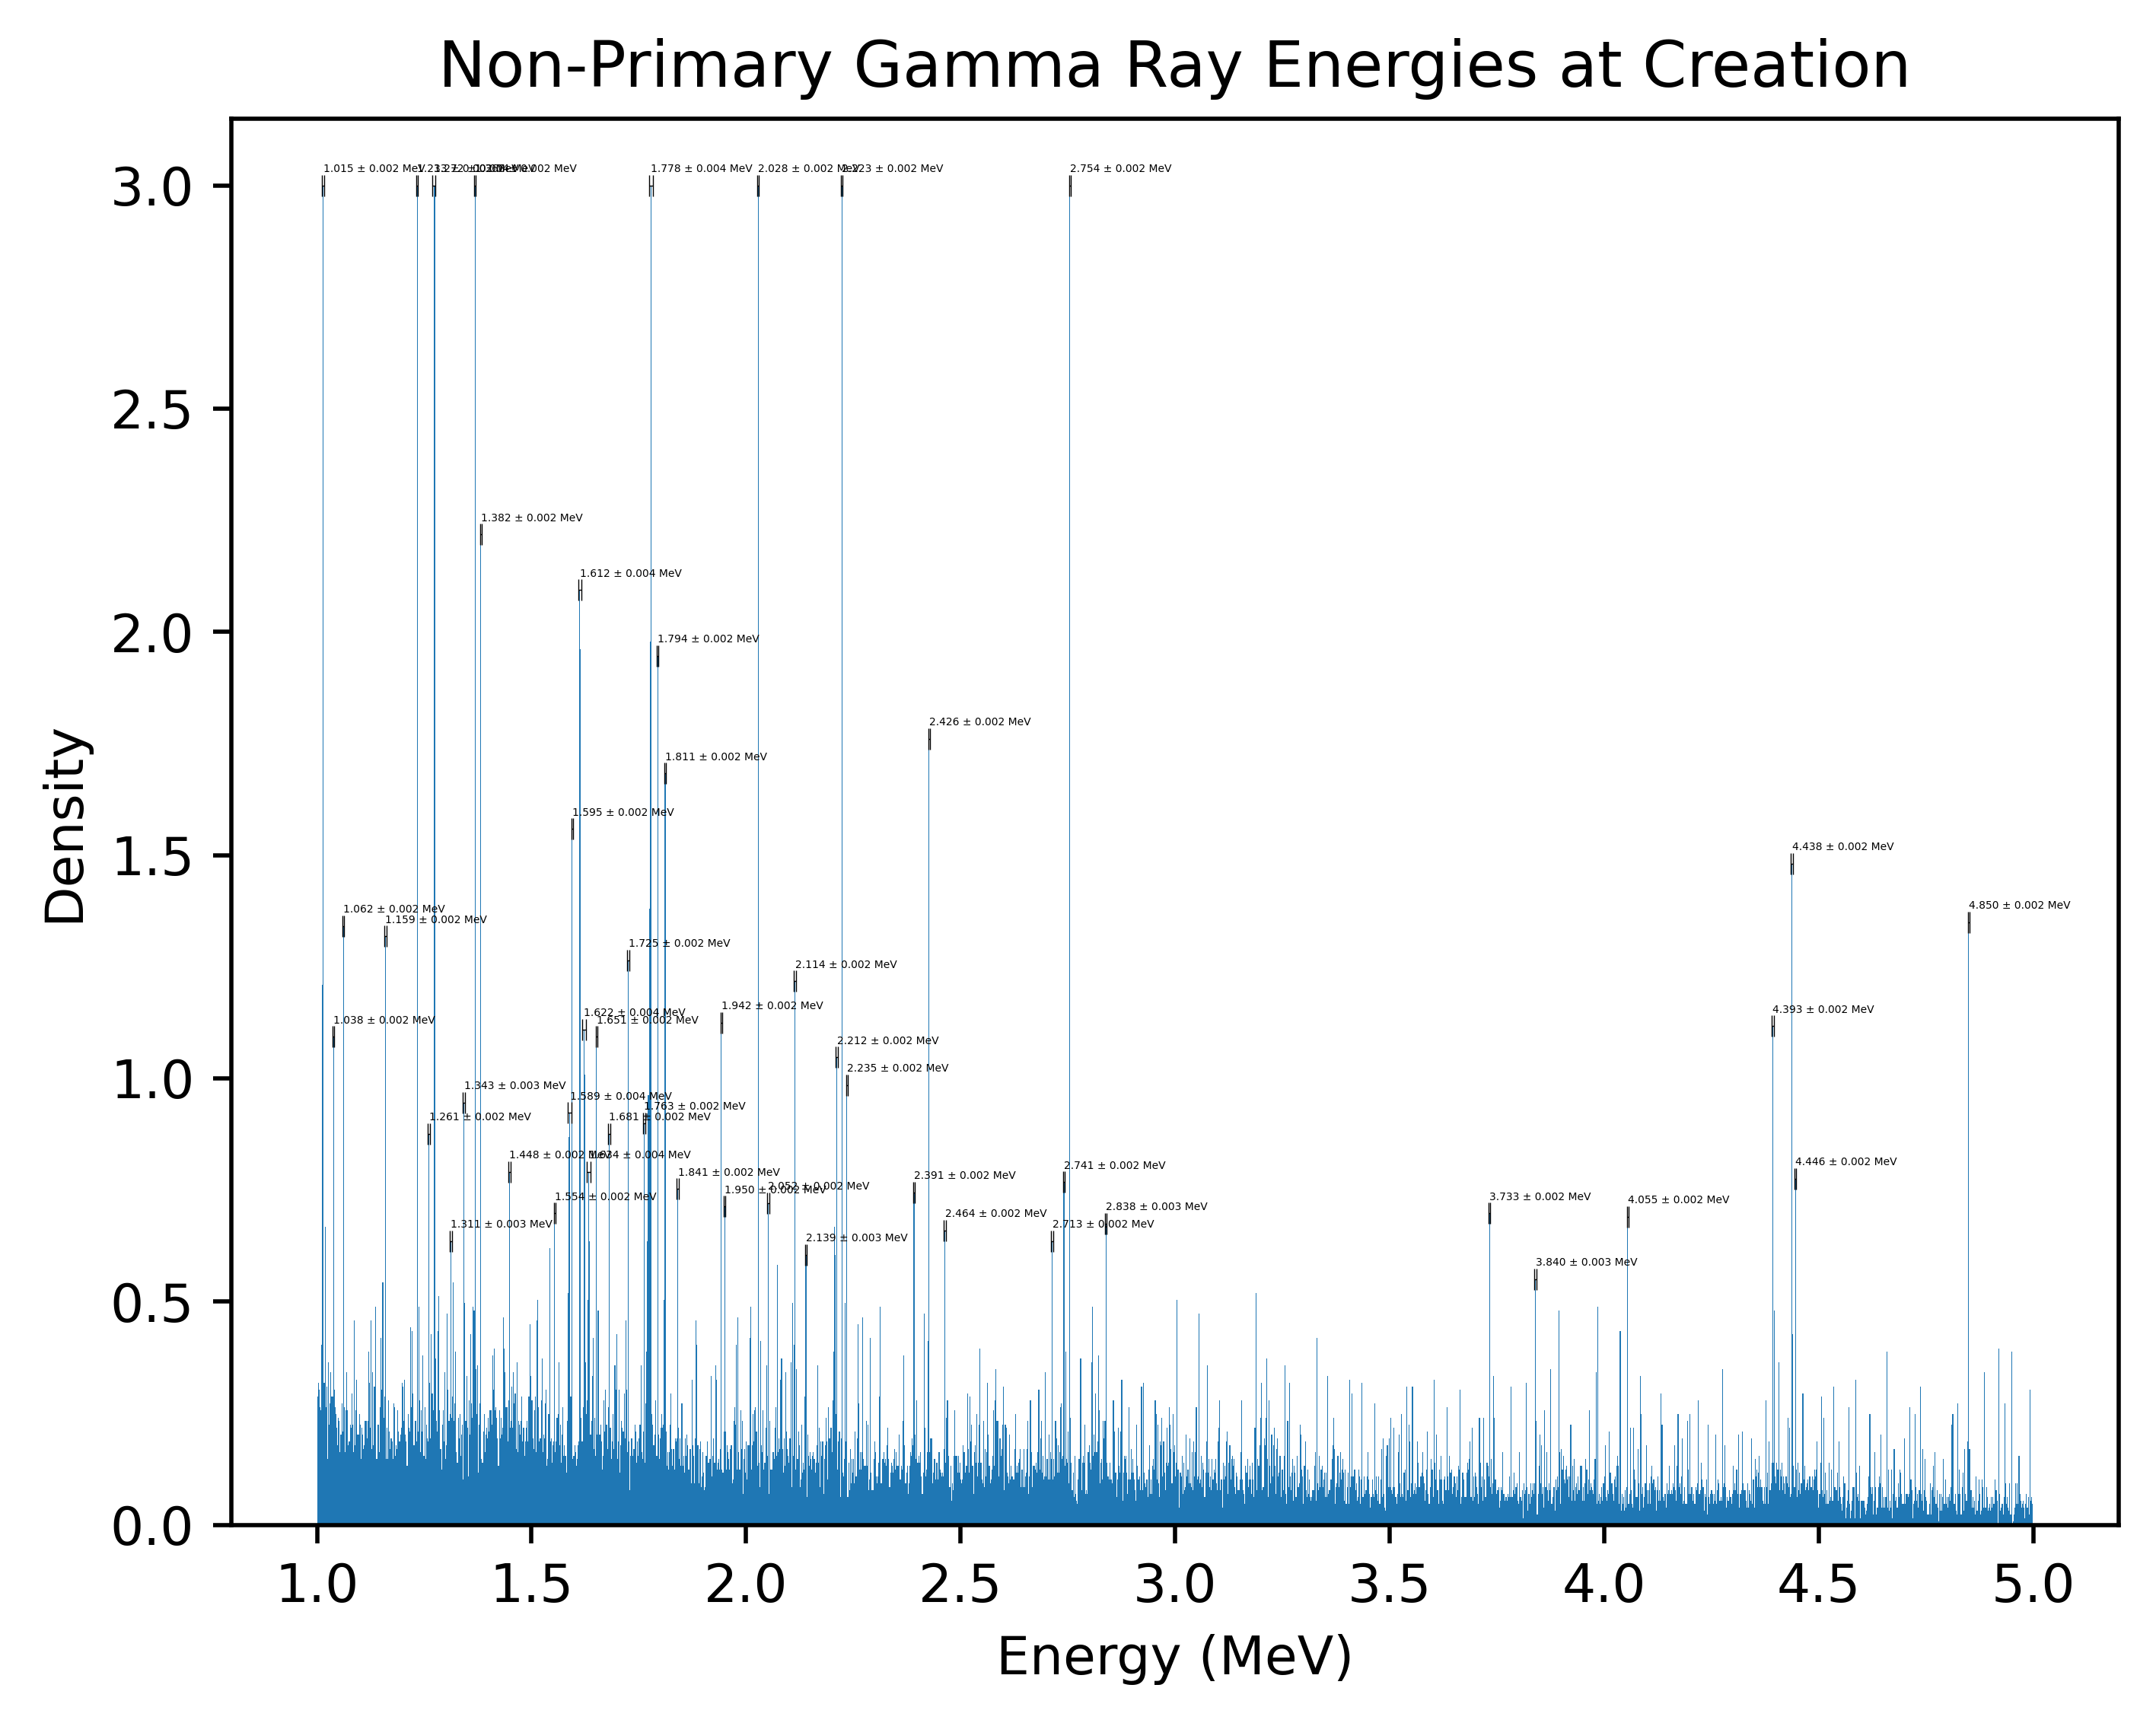

In [26]:
def plot_energy_spectrum(
    e_low, e_high, n_bins=512, prominence=None, clip=None, text_size=5
):
    energies = df[
        energy_range(e_low, e_high) & exclude_processes(["eBrem", "annihil"])
    ]["E"]
    plot_with_peaks(
        data=energies,
        n_bins=n_bins,
        prominence=prominence,
        xlabel="Energy (MeV)",
        title="Non-Primary Gamma Ray Energies at Creation",
        clip_counts=clip,
        text_size=text_size,
    )


plot_energy_spectrum(1.0, 5.0, n_bins=2048, prominence=0.5, clip=3, text_size=2)

## Depth Profiles

In [27]:
process_names, process_counts = np.unique(df["creator"], return_counts=True)
process_counts, process_names = zip(*sorted(zip(process_counts, process_names))[::-1])

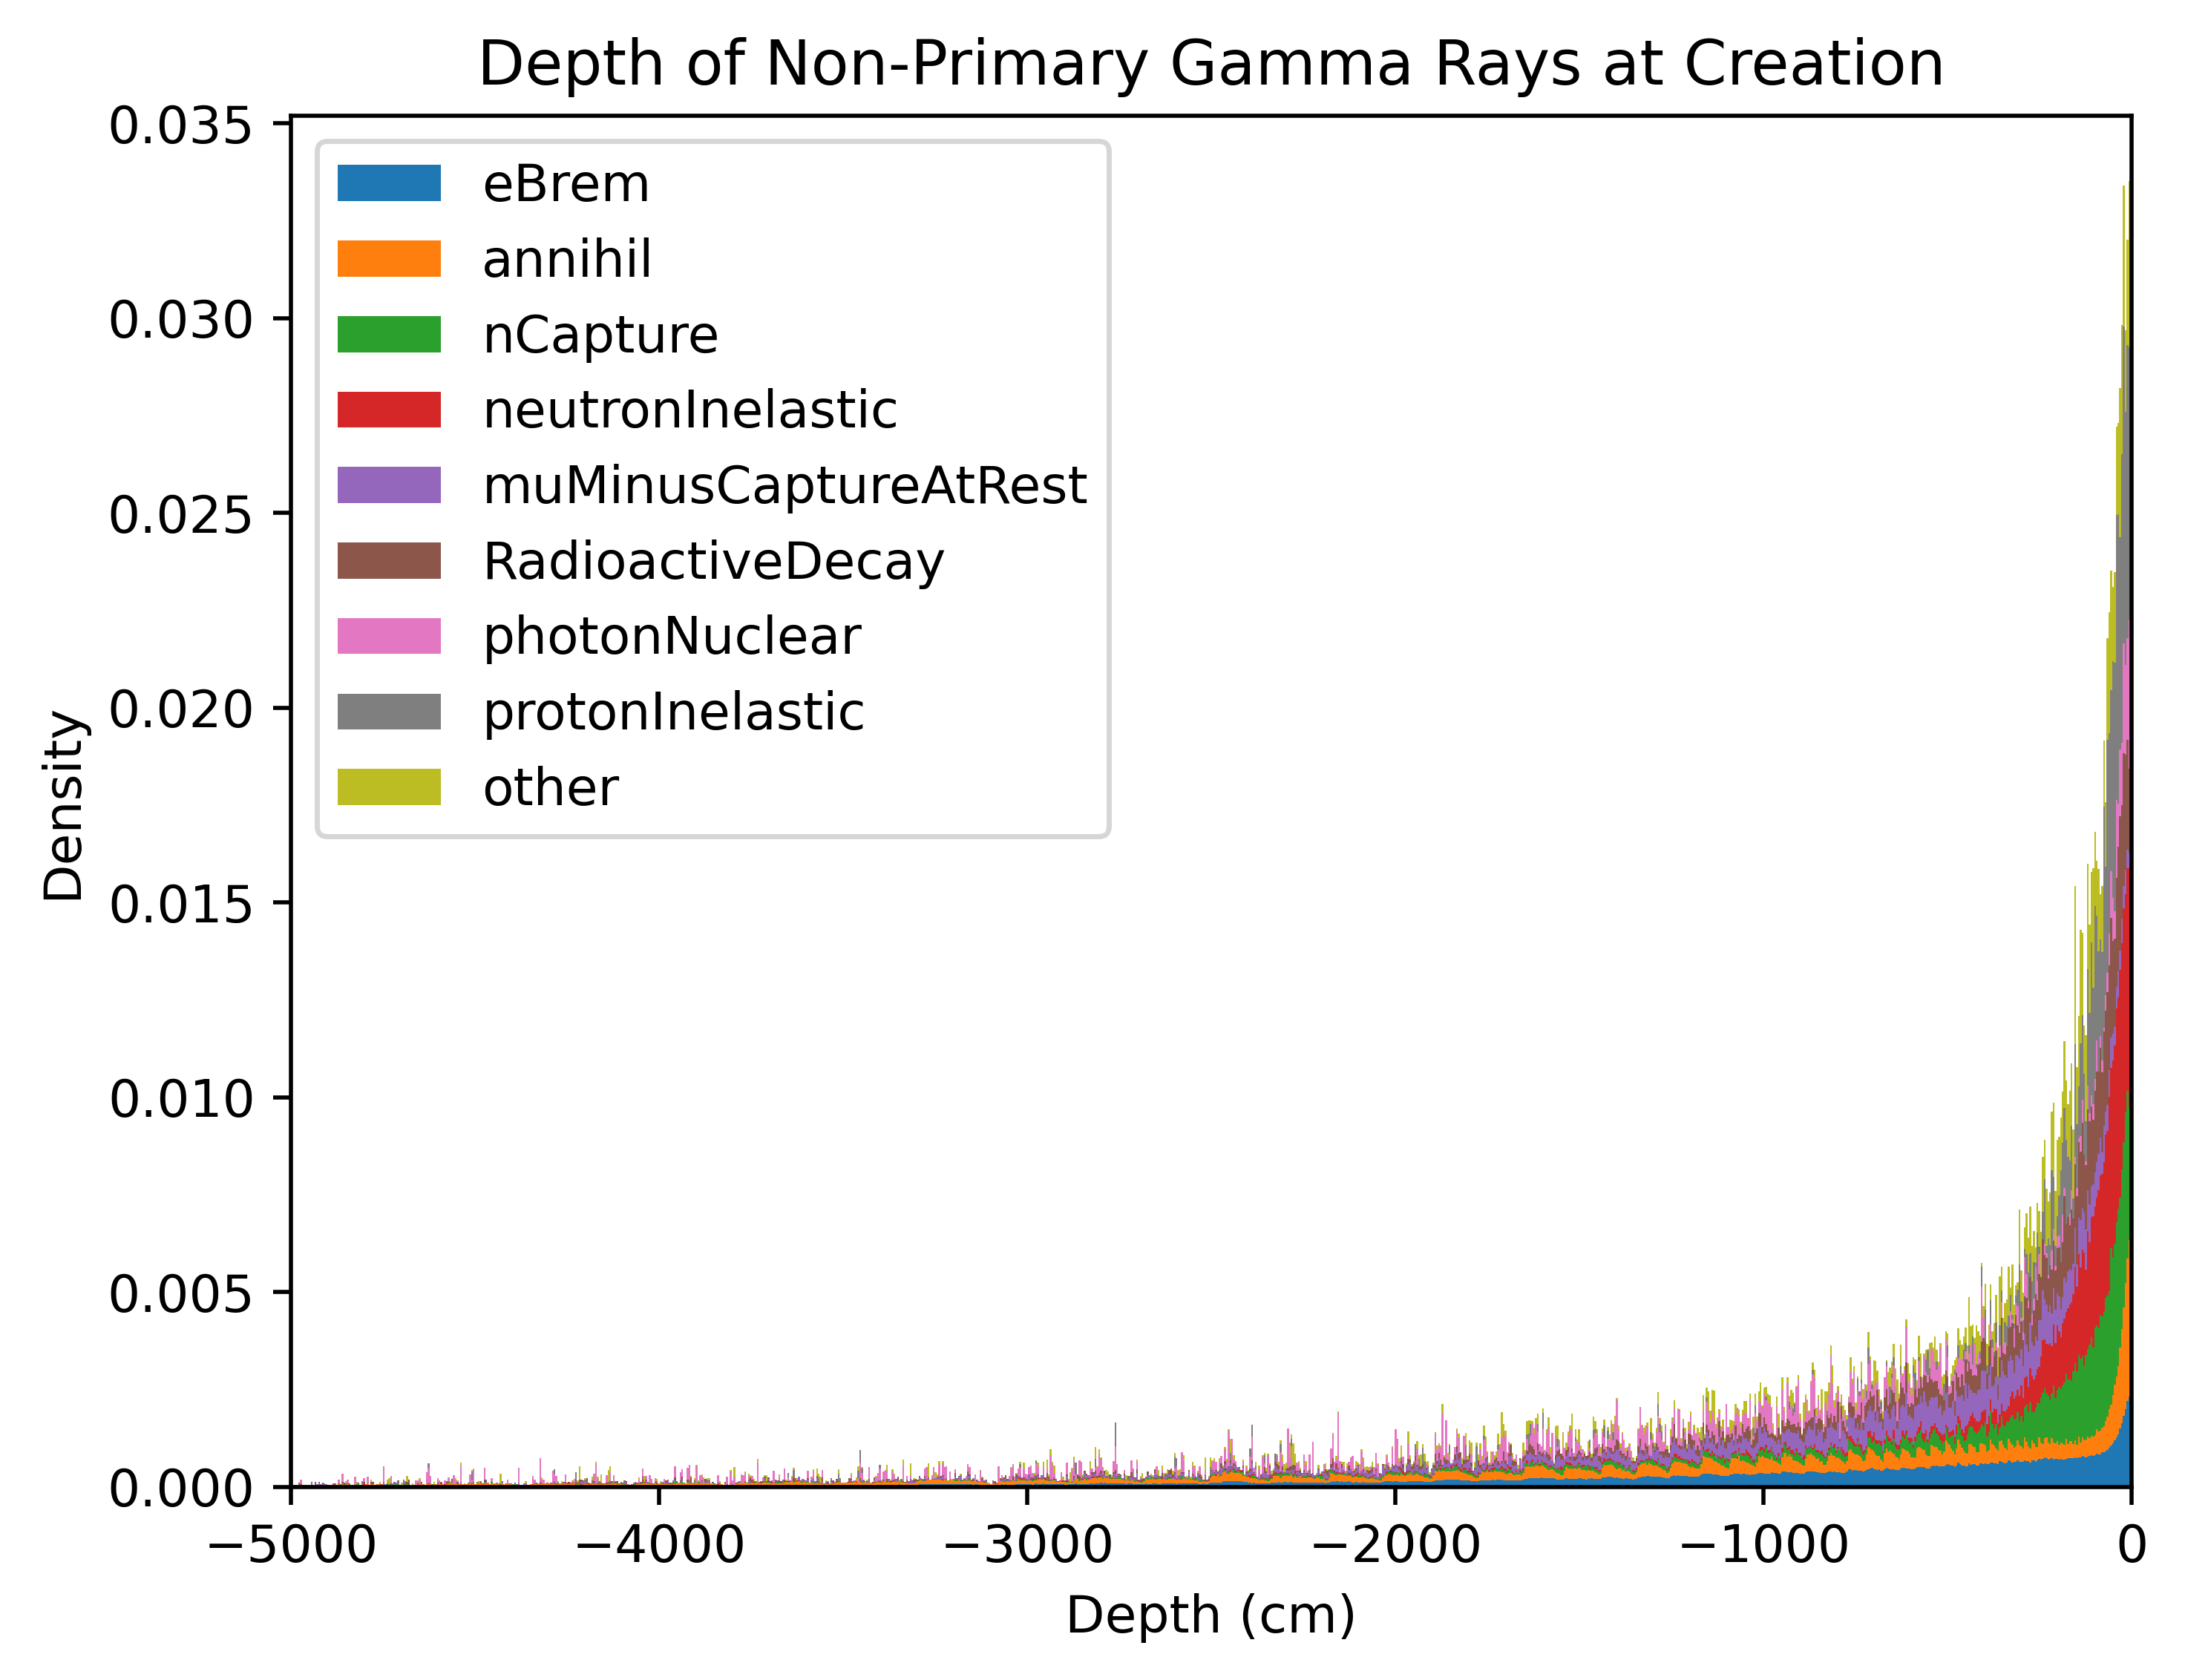

In [28]:
# plt.yscale("log")
plot_with_peaks(
    data=[df[include_processes([name])]["z"] / 10 for name in process_names[:8]]
    + [df[exclude_processes(process_names[:8])]["z"] / 10],
    n_bins=1024,
    xlabel="Depth (cm)",
    title="Depth of Non-Primary Gamma Rays at Creation",
    xlims=(-5000, 0),
    stacked=True,
    legend=list(process_names[:8]) + ["other"],
    bin_range=(-5000, 0),
)

mean     -395.946650
median   -141.967000
std       673.666117
Name: z, dtype: float64


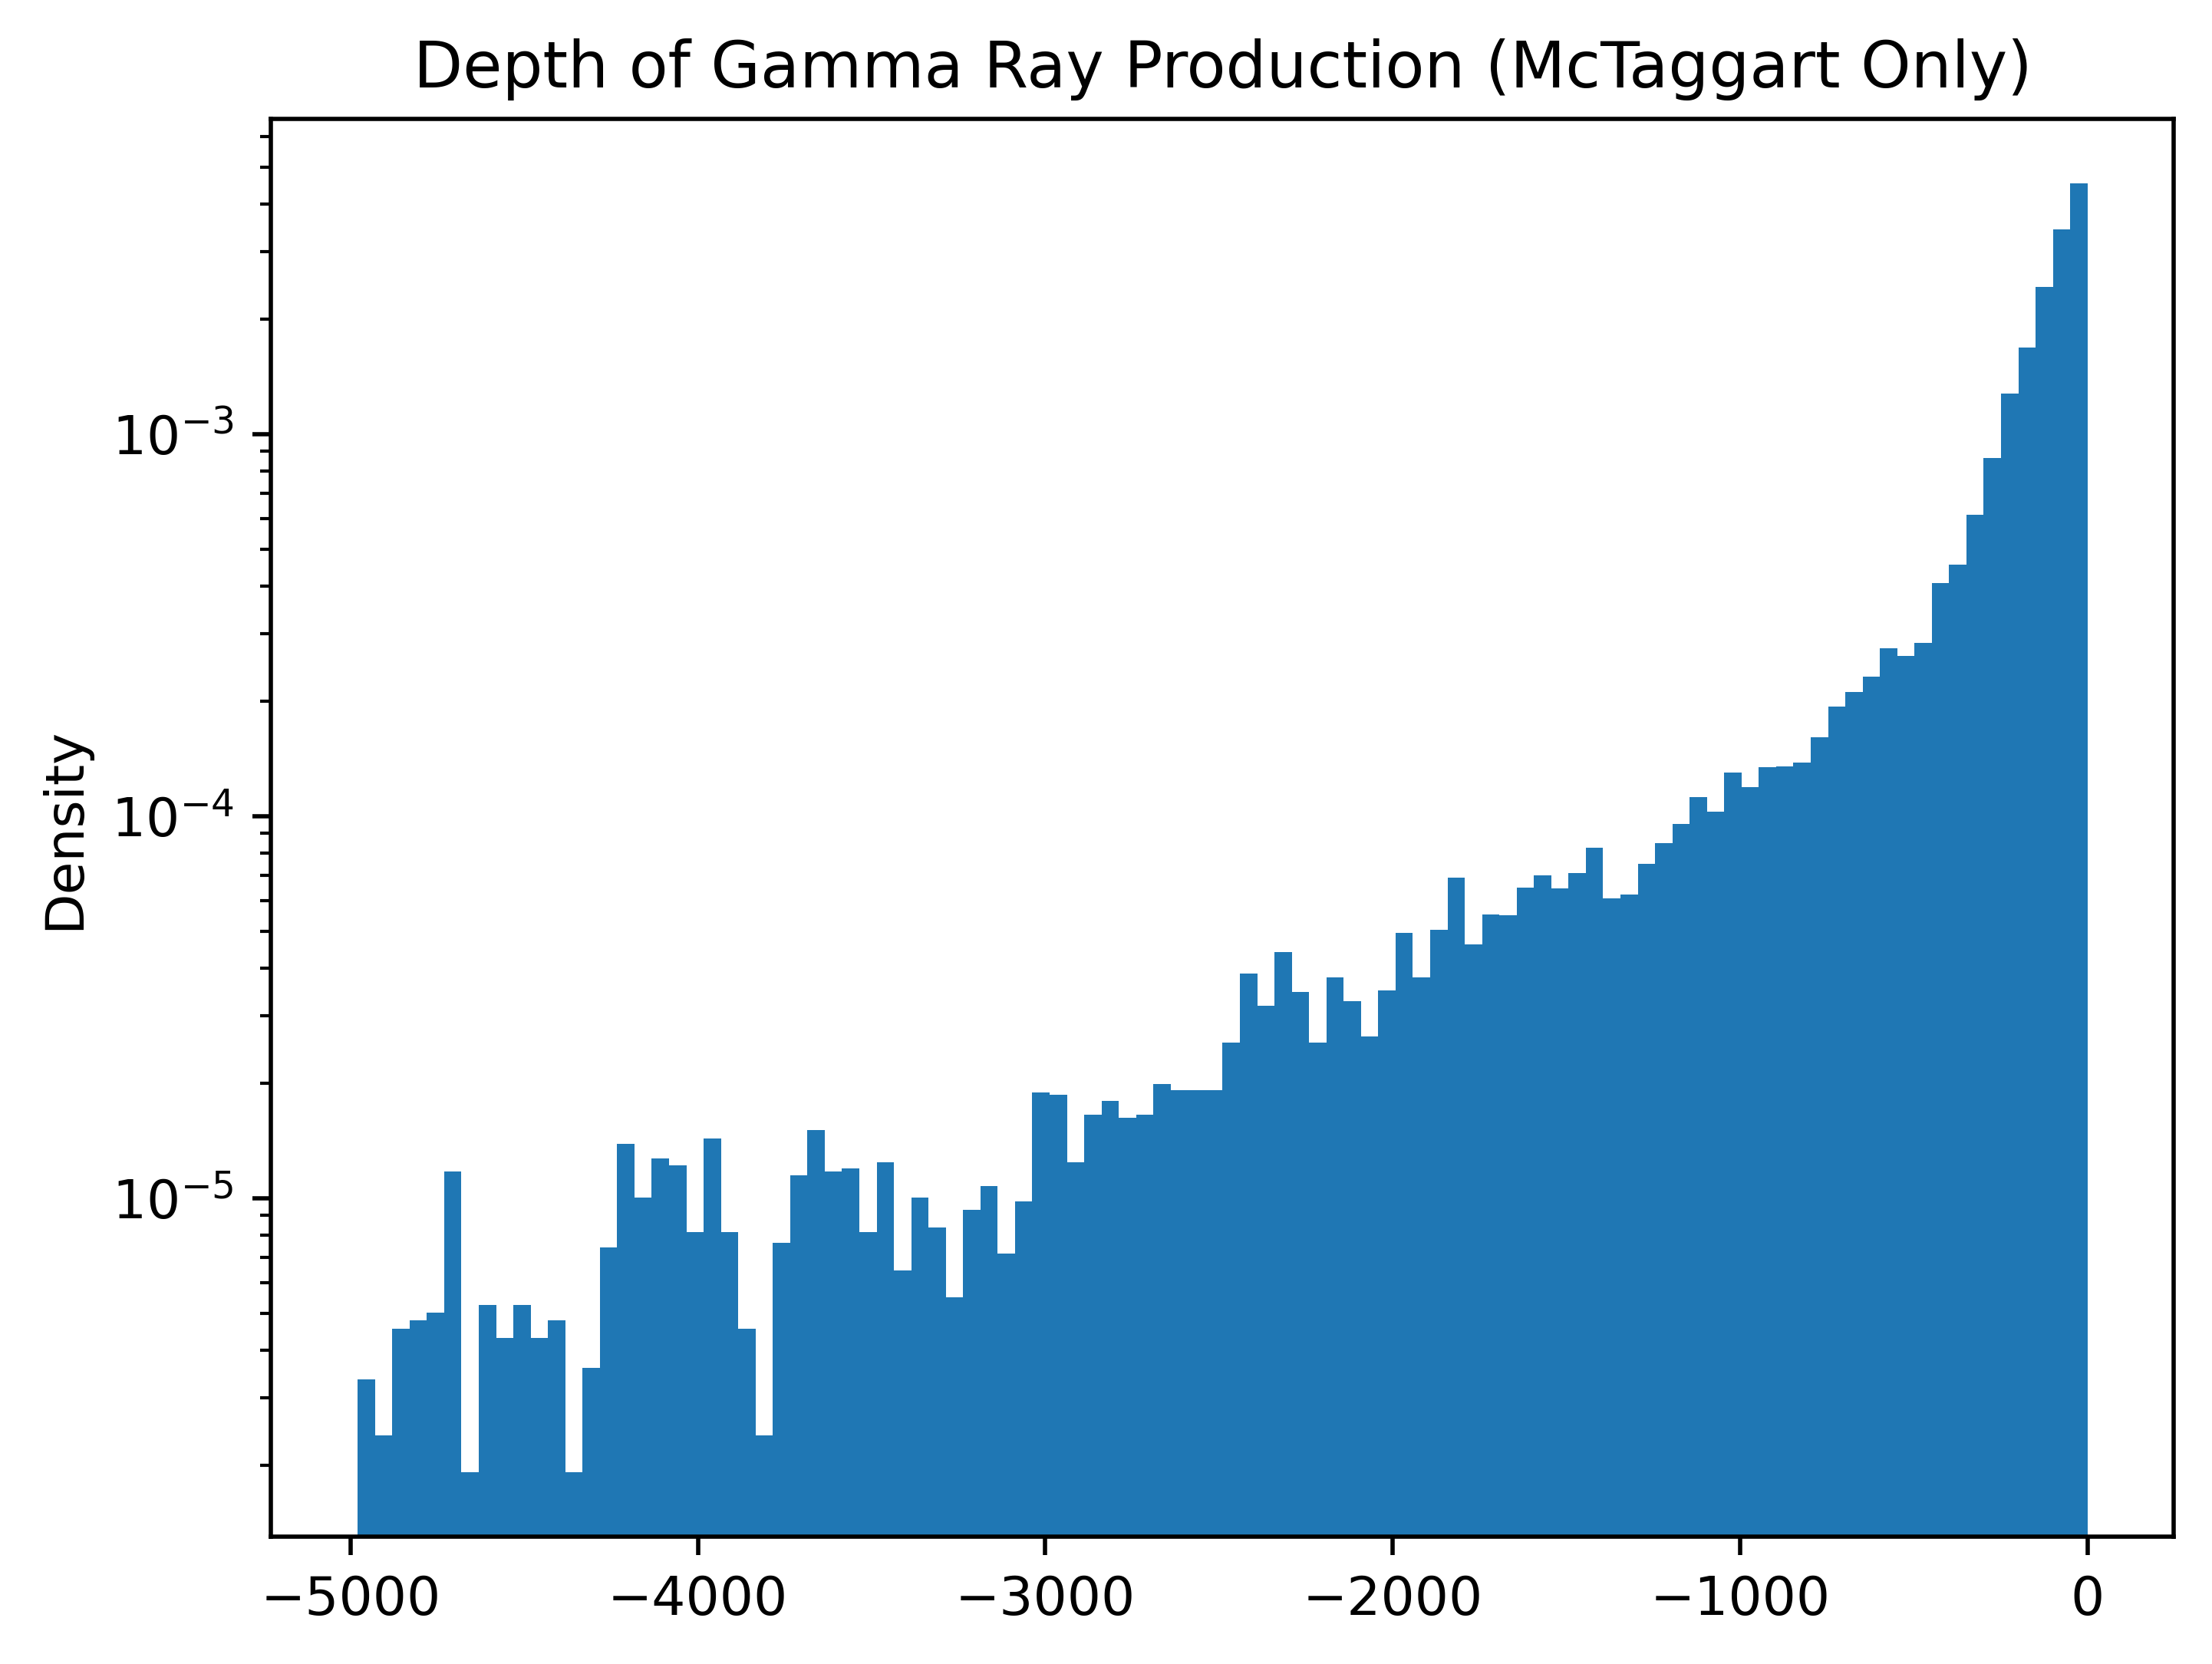

In [29]:
mctaggart = include_processes(["neutronInelastic", "nCapture", "RadioactiveDecay"])
print(df[mctaggart]["z"].aggregate(["mean", "median", "std"]) / 10)
plt.yscale("log")
plot_with_peaks(
    df[mctaggart]["z"] / 10, 100, title="Depth of Gamma Ray Production (McTaggart Only)"
)

## Creation Processes

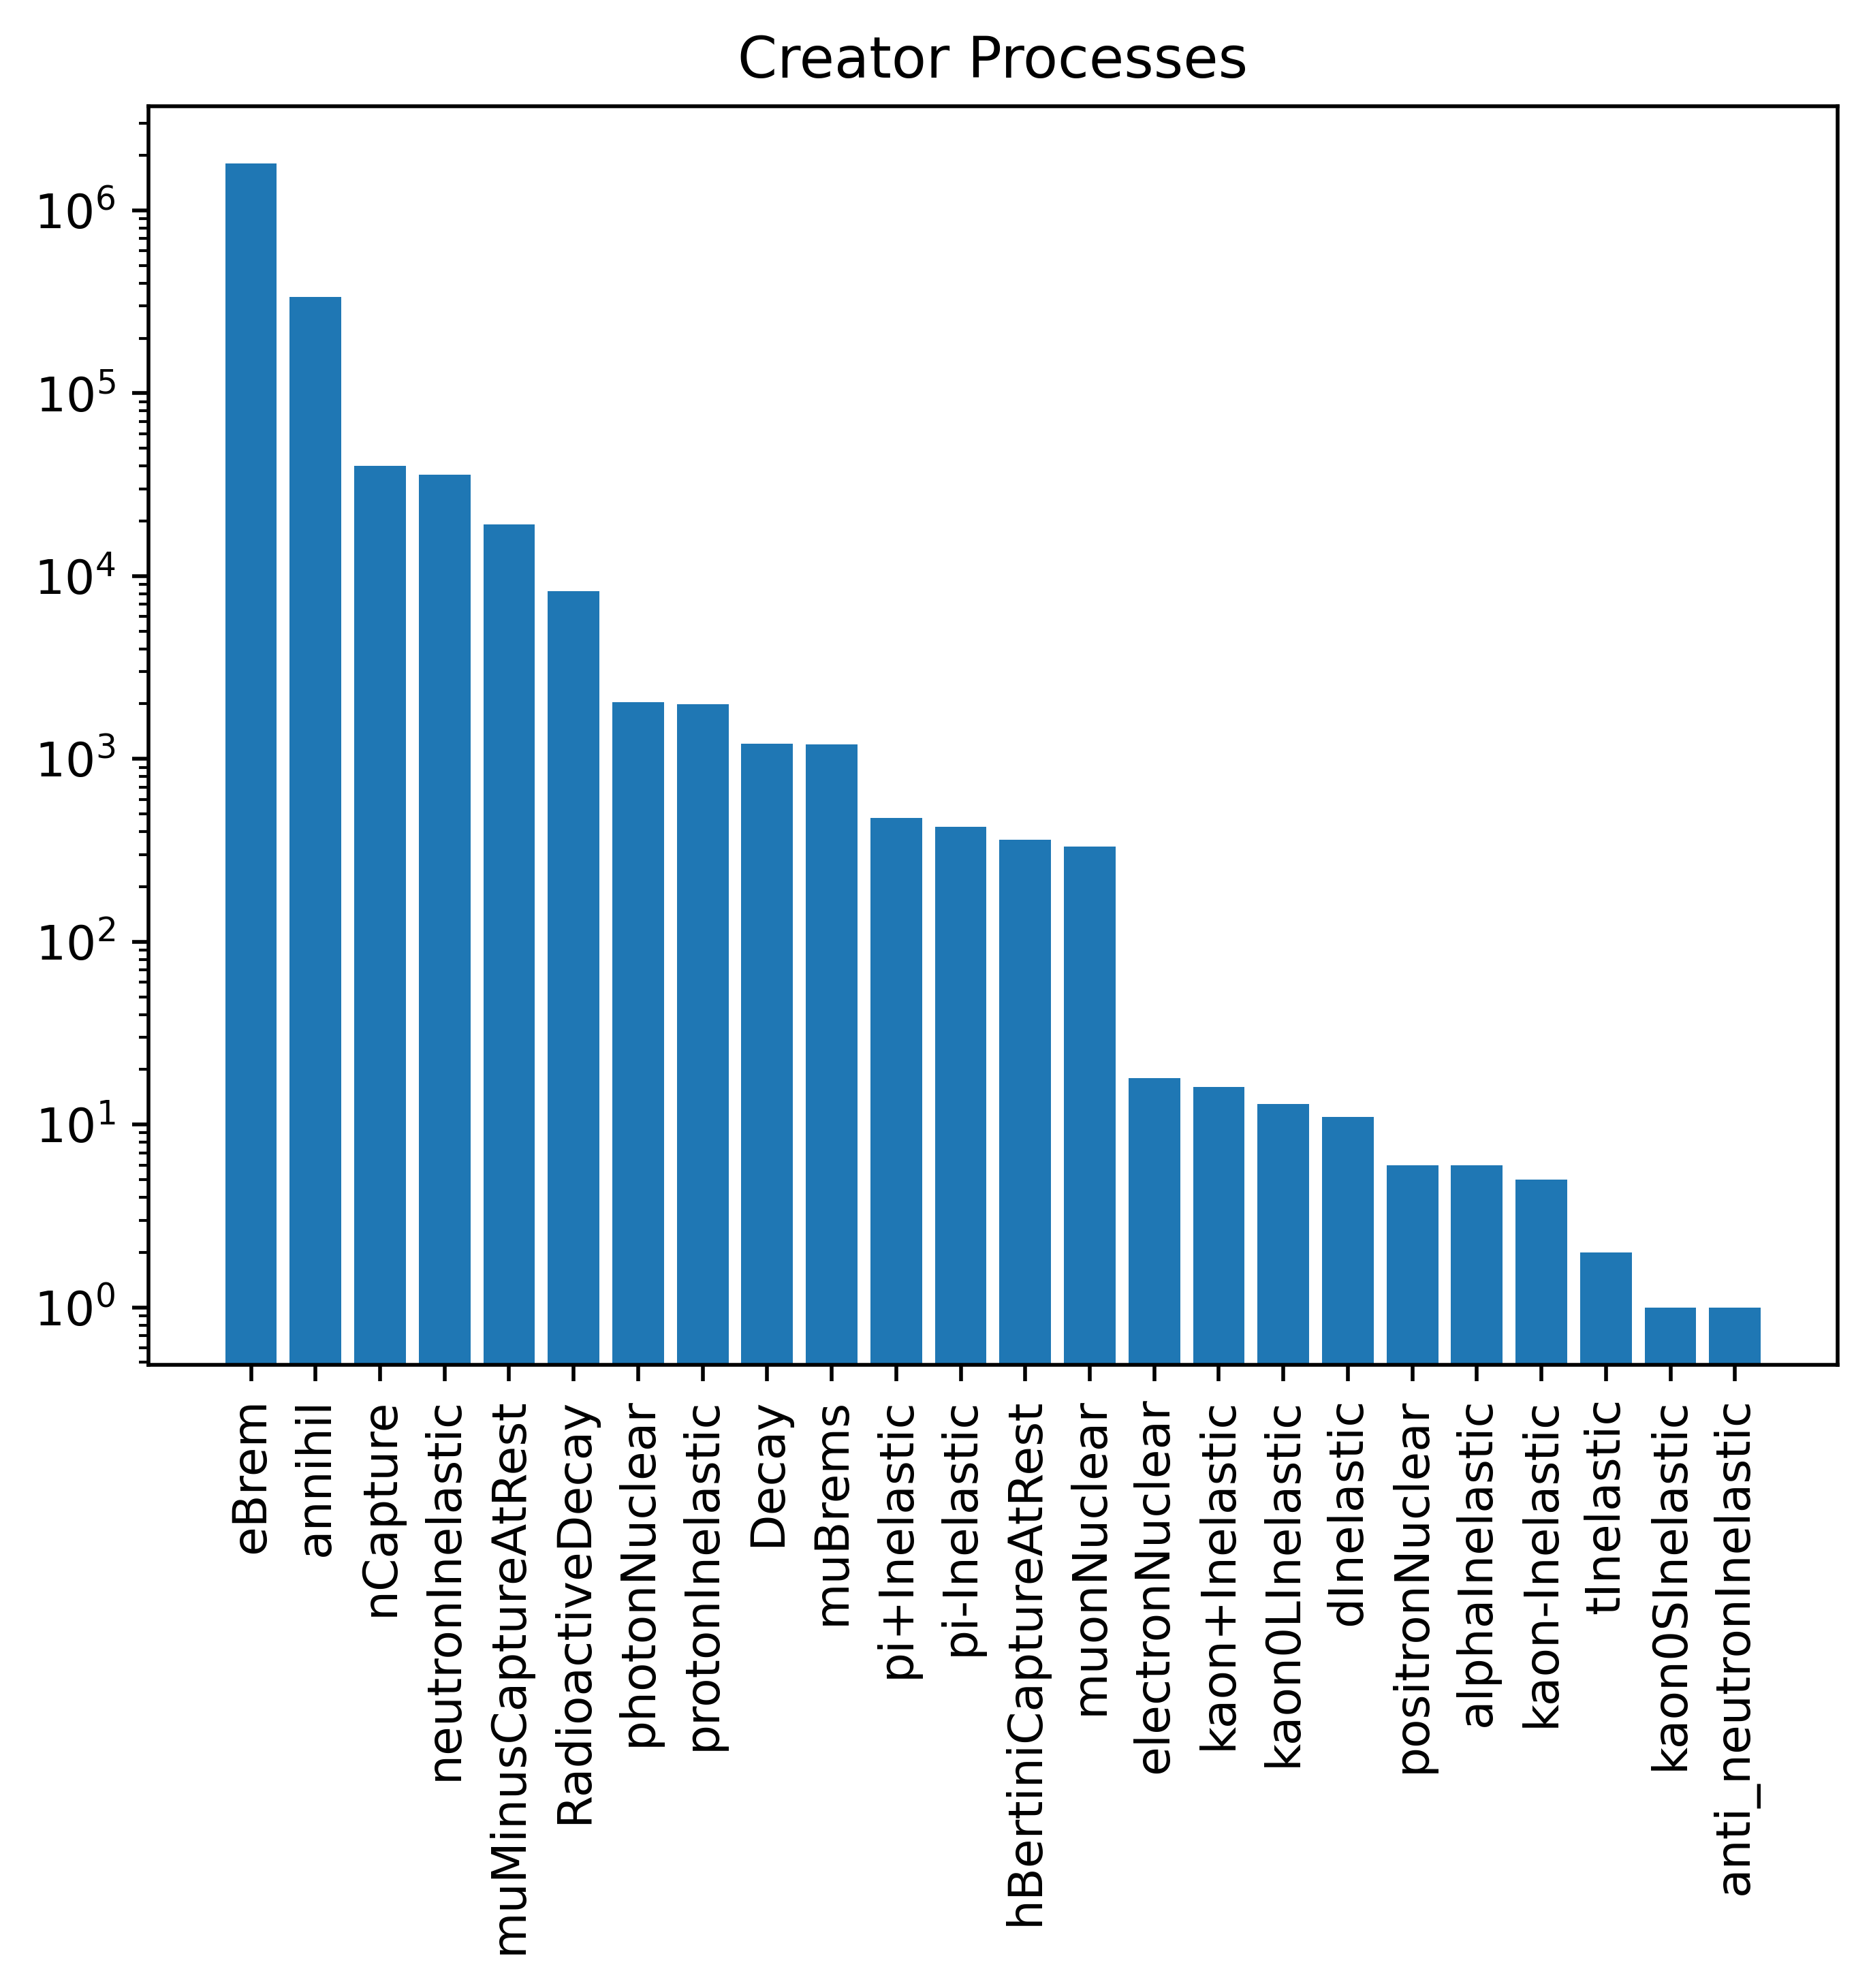

In [30]:
plt.yscale("log")
plt.bar(process_names, process_counts)
plt.xticks(rotation="vertical")
plt.title("Creator Processes")
plt.show()

In [31]:
print(
    f"{100*df[include_processes(["eBrem"])].size / df.size:.1f}% of gamma rays generated by Bremsstrahlung radiation"
)

80.2% of gamma rays generated by Bremsstrahlung radiation


## Time of Creation

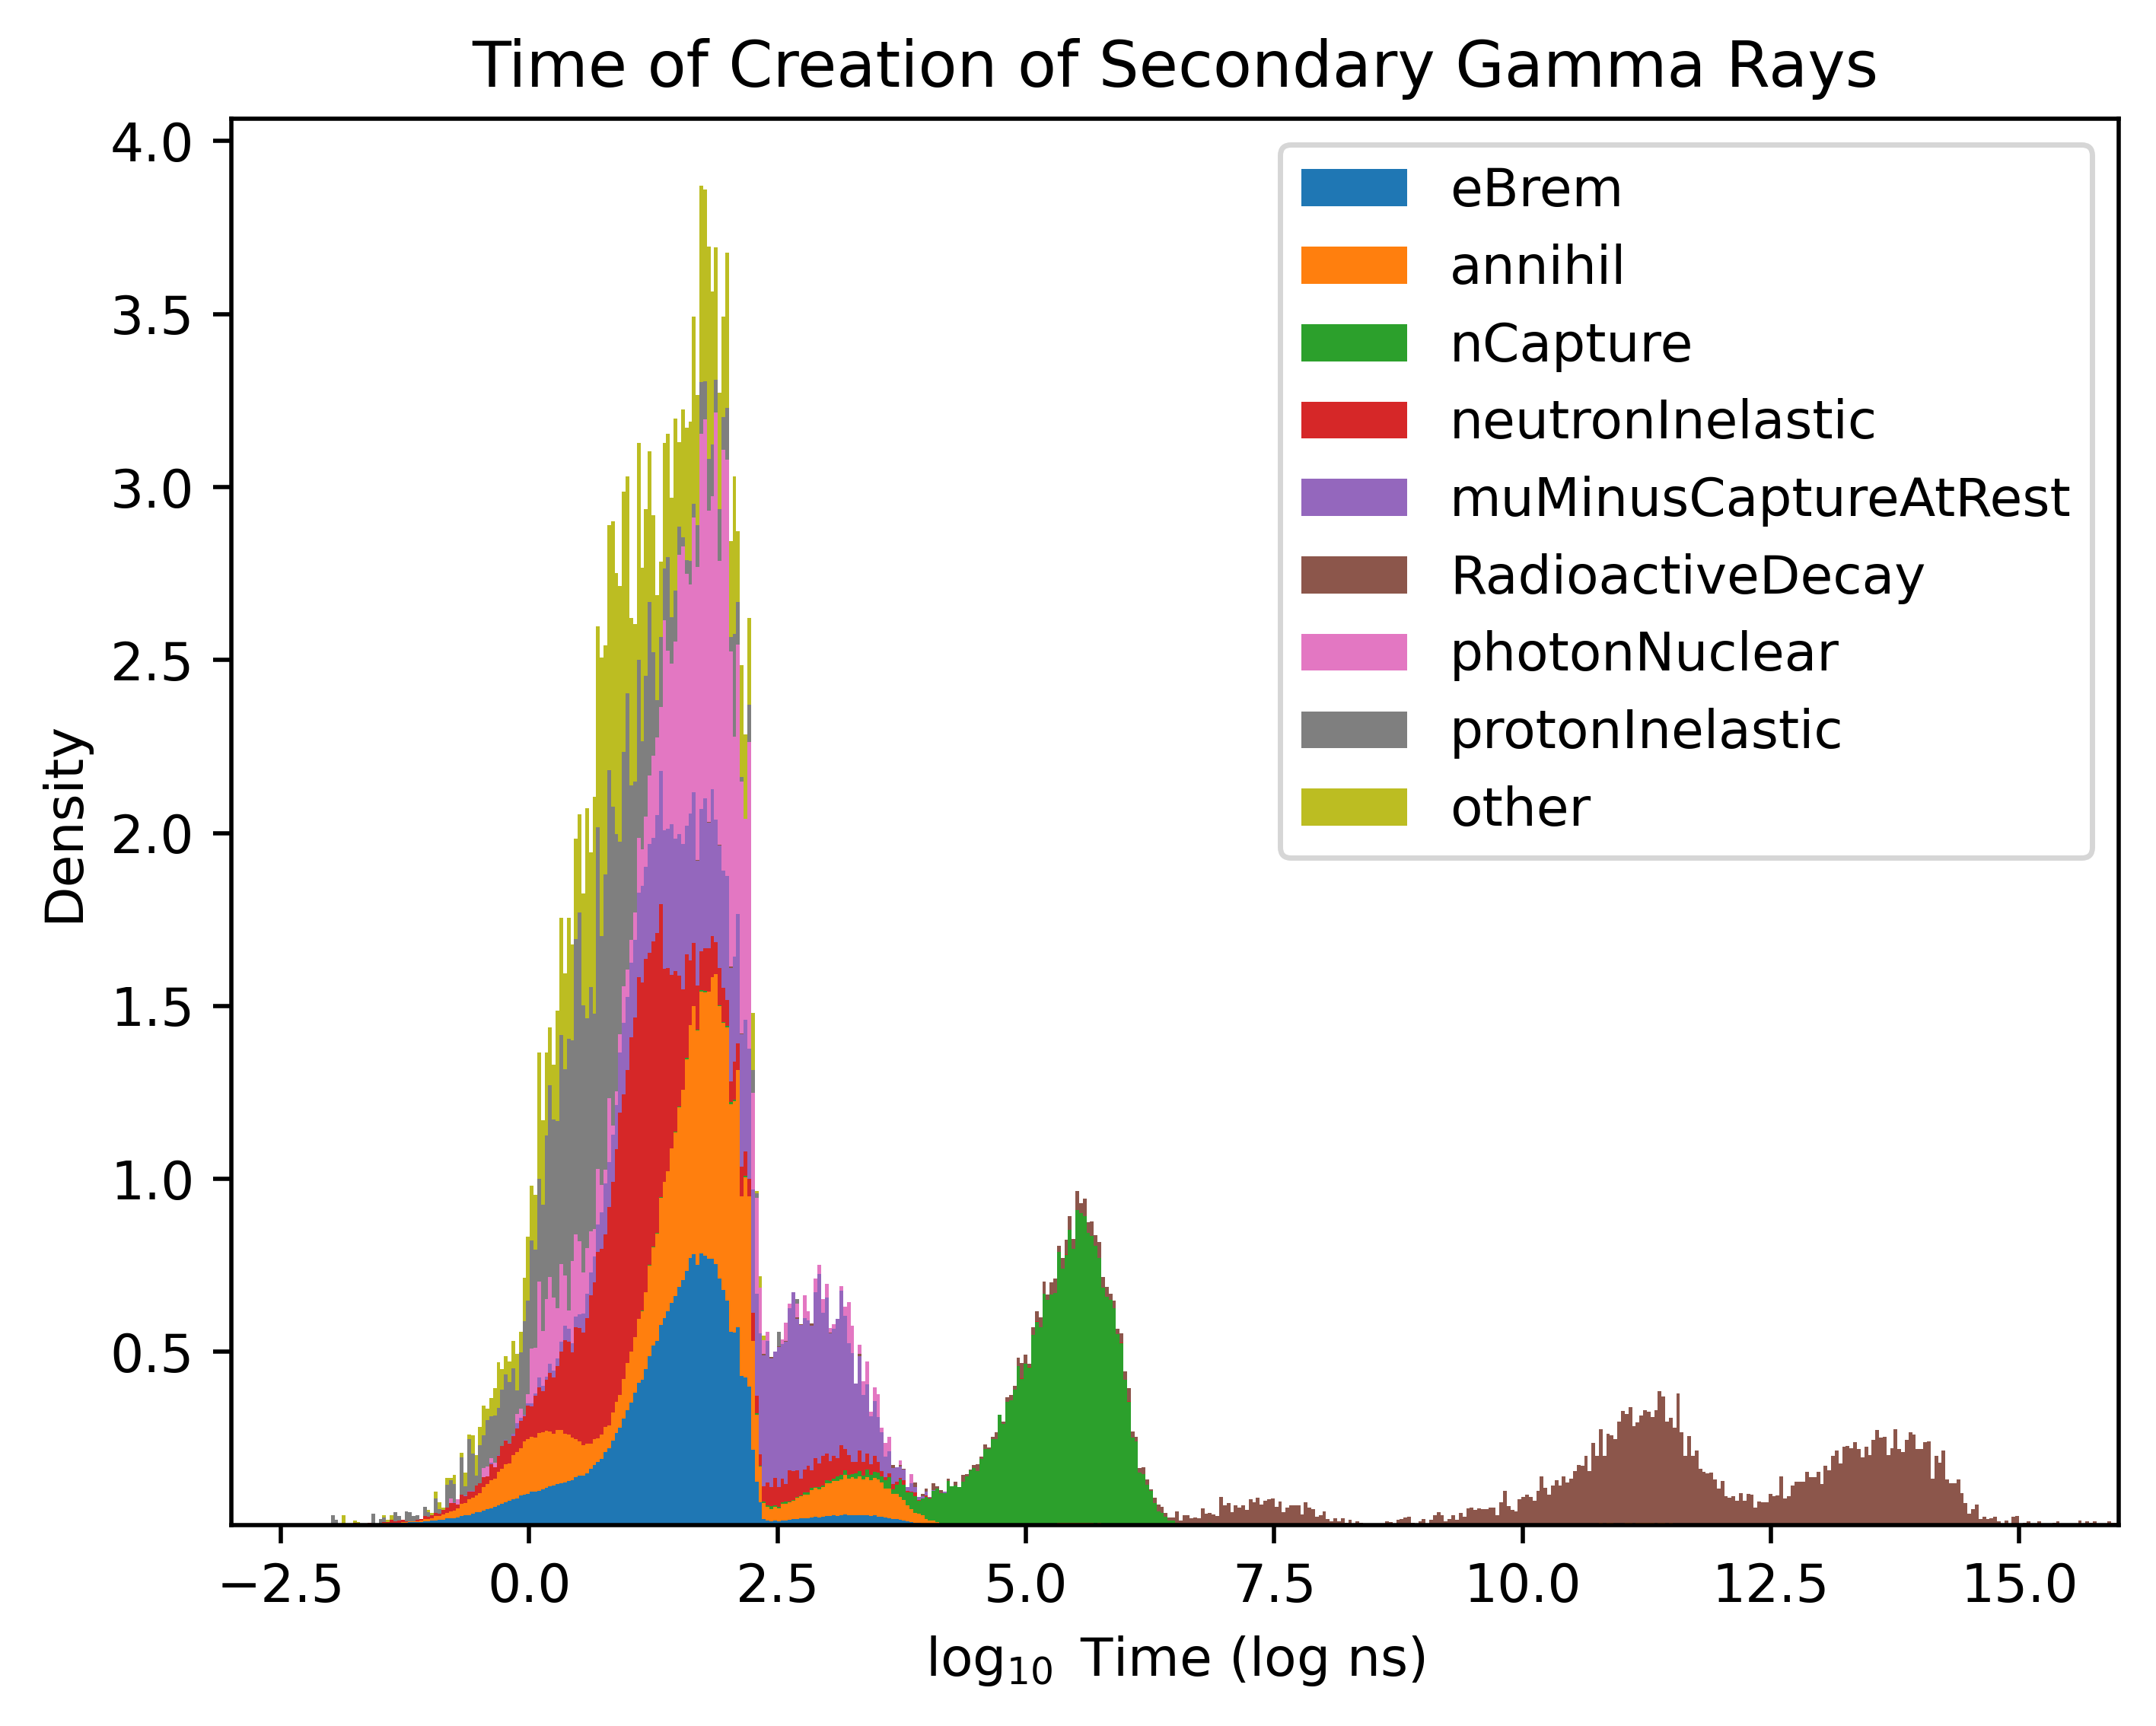

In [32]:
plot_with_peaks(
    data=[np.log10(df[include_processes([name])]["time"]) for name in process_names[:8]]
    + [np.log10(df[exclude_processes(process_names[:8])]["time"])],
    n_bins=512,
    title="Time of Creation of Secondary Gamma Rays",
    xlabel="$\\log_{10}$ Time (log ns)",
    stacked=True,
    legend=list(process_names[:8]) + ["other"],
    bin_range=(-3.0, 16.0),
    xlims=(-3.0, 16.0),
)

## Isotropy/Anisotropy

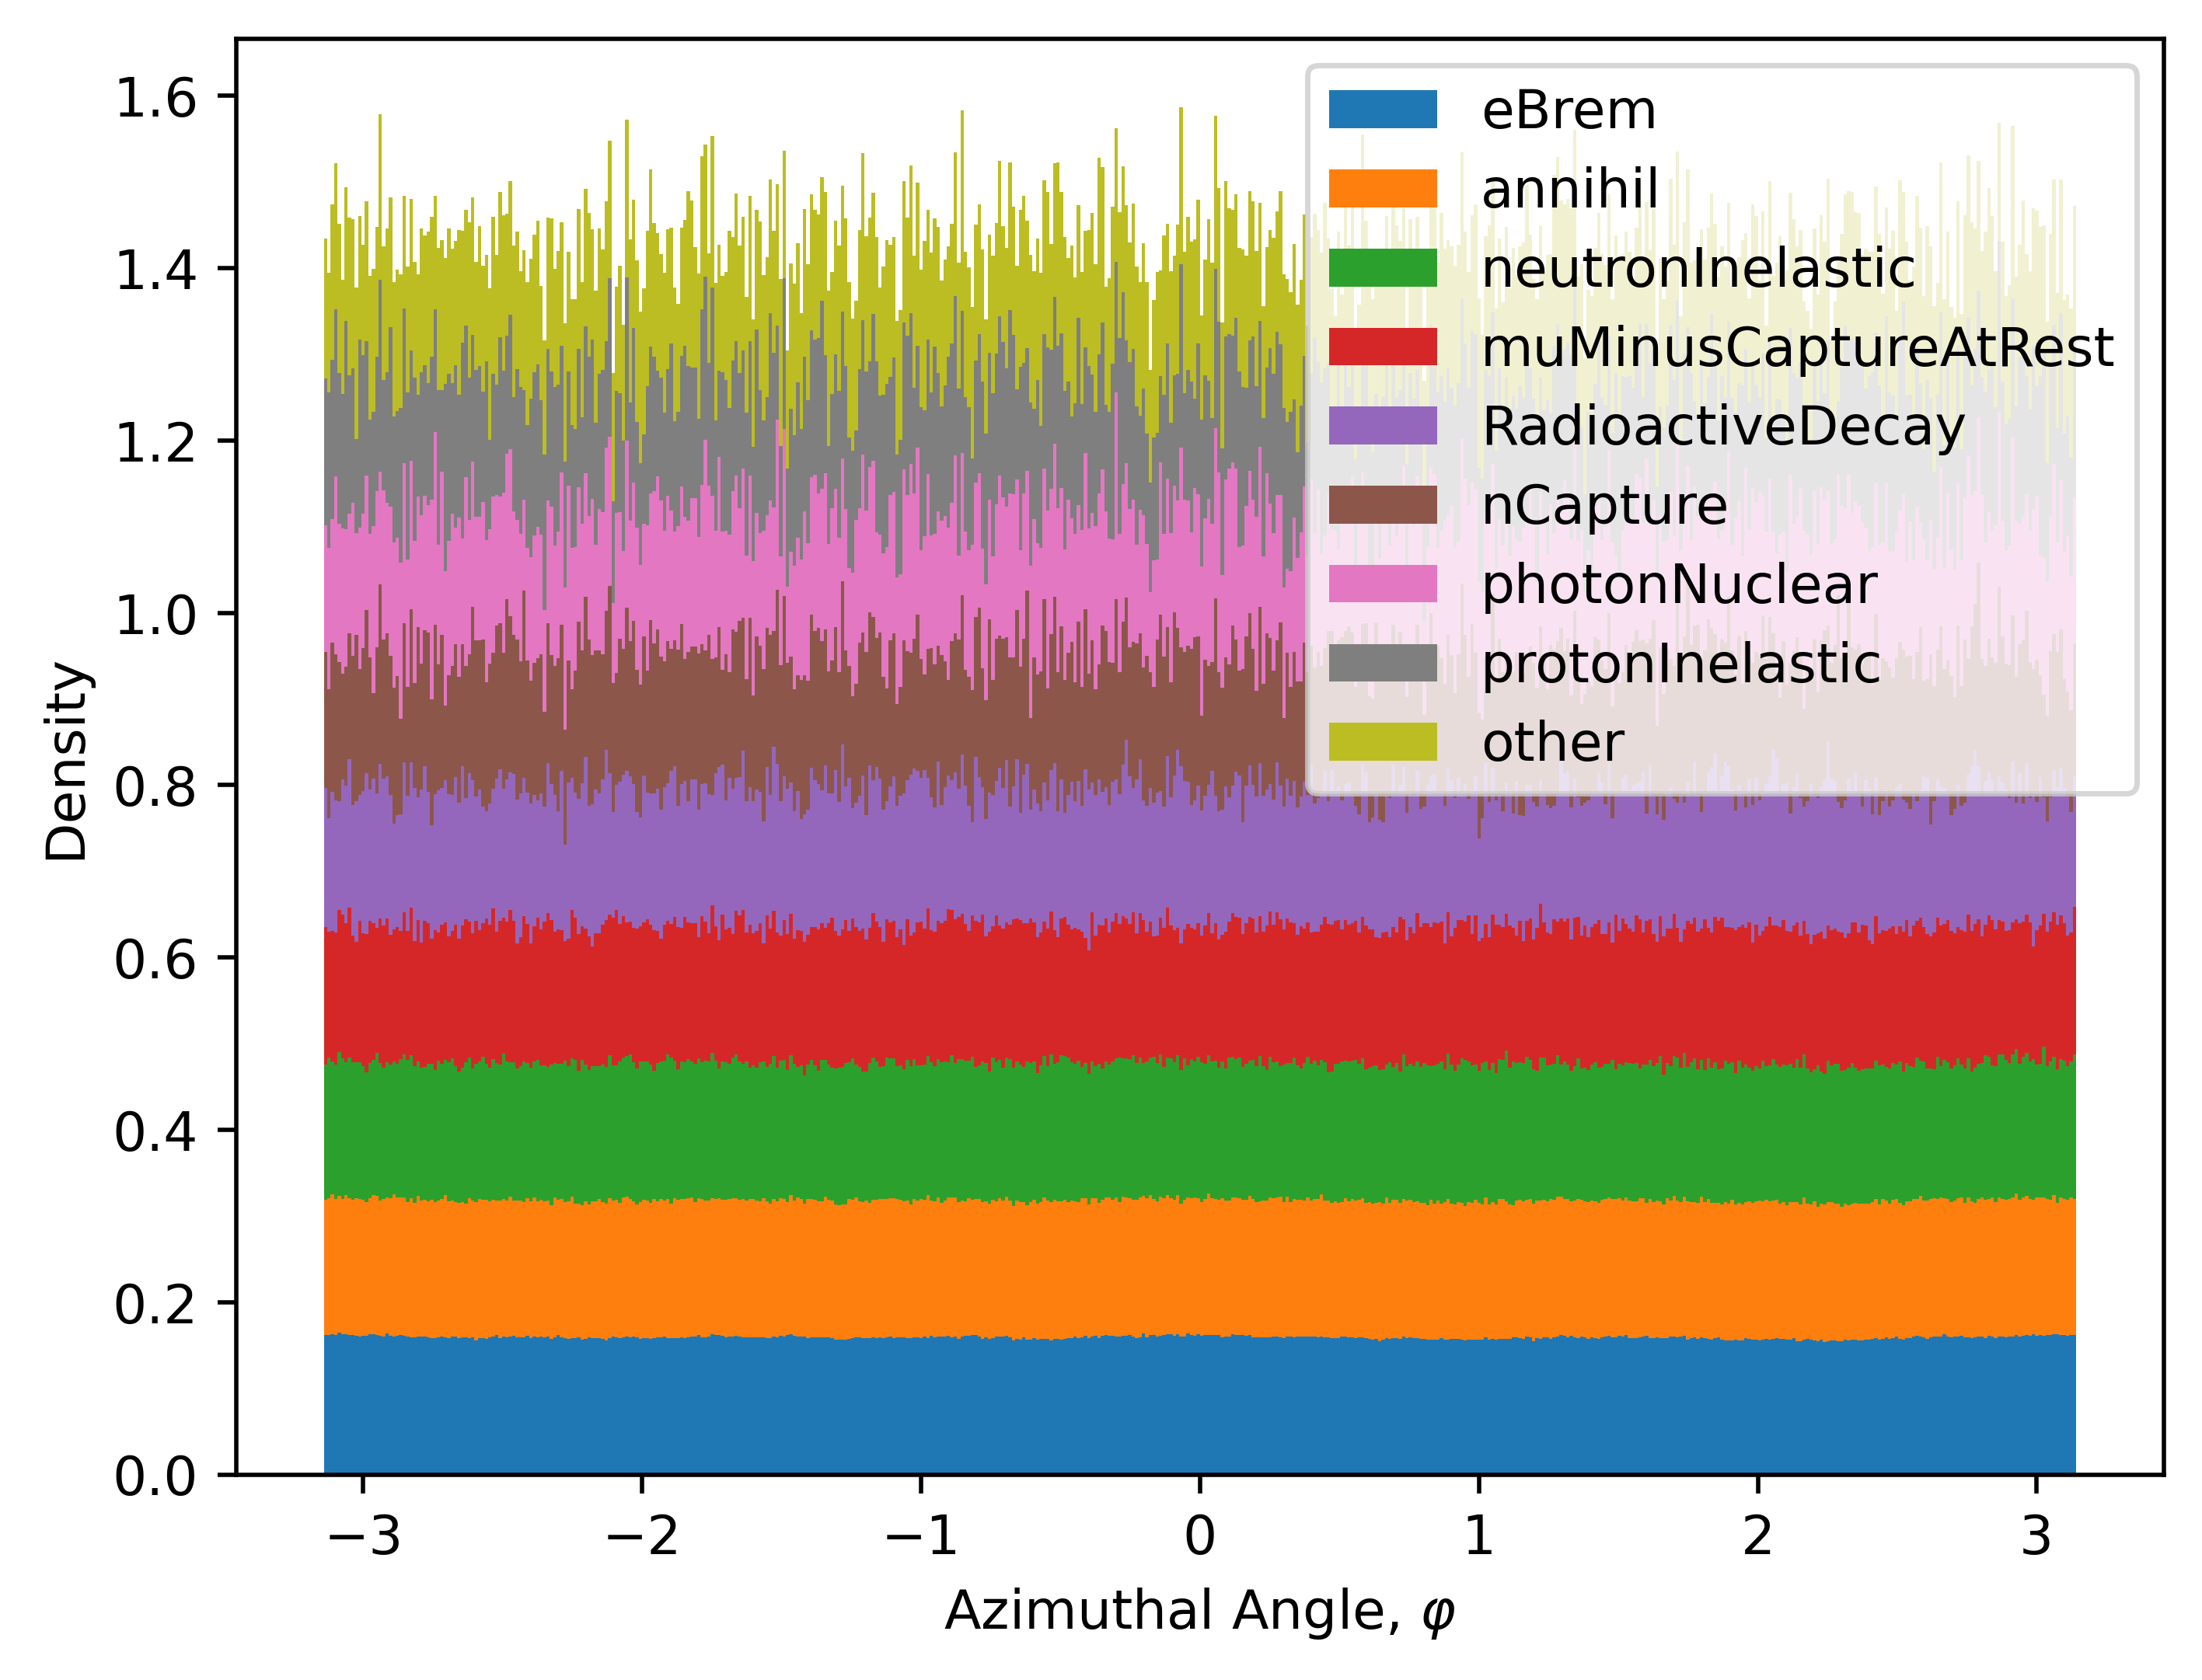

In [14]:
plot_with_peaks(
    [
        np.atan2(
            df[include_processes([name])]["p_x"], df[include_processes([name])]["p_y"]
        )
        for name in process_names[:8]
    ]
    + [
        np.atan2(
            df[exclude_processes(process_names[:8])]["p_x"],
            df[exclude_processes(process_names[:8])]["p_y"],
        )
    ],
    512,
    xlabel="Azimuthal Angle, $\\varphi$",
    stacked=True,
    legend=list(process_names[:8]) + ["other"],
    bin_range=(-np.pi, np.pi),
)

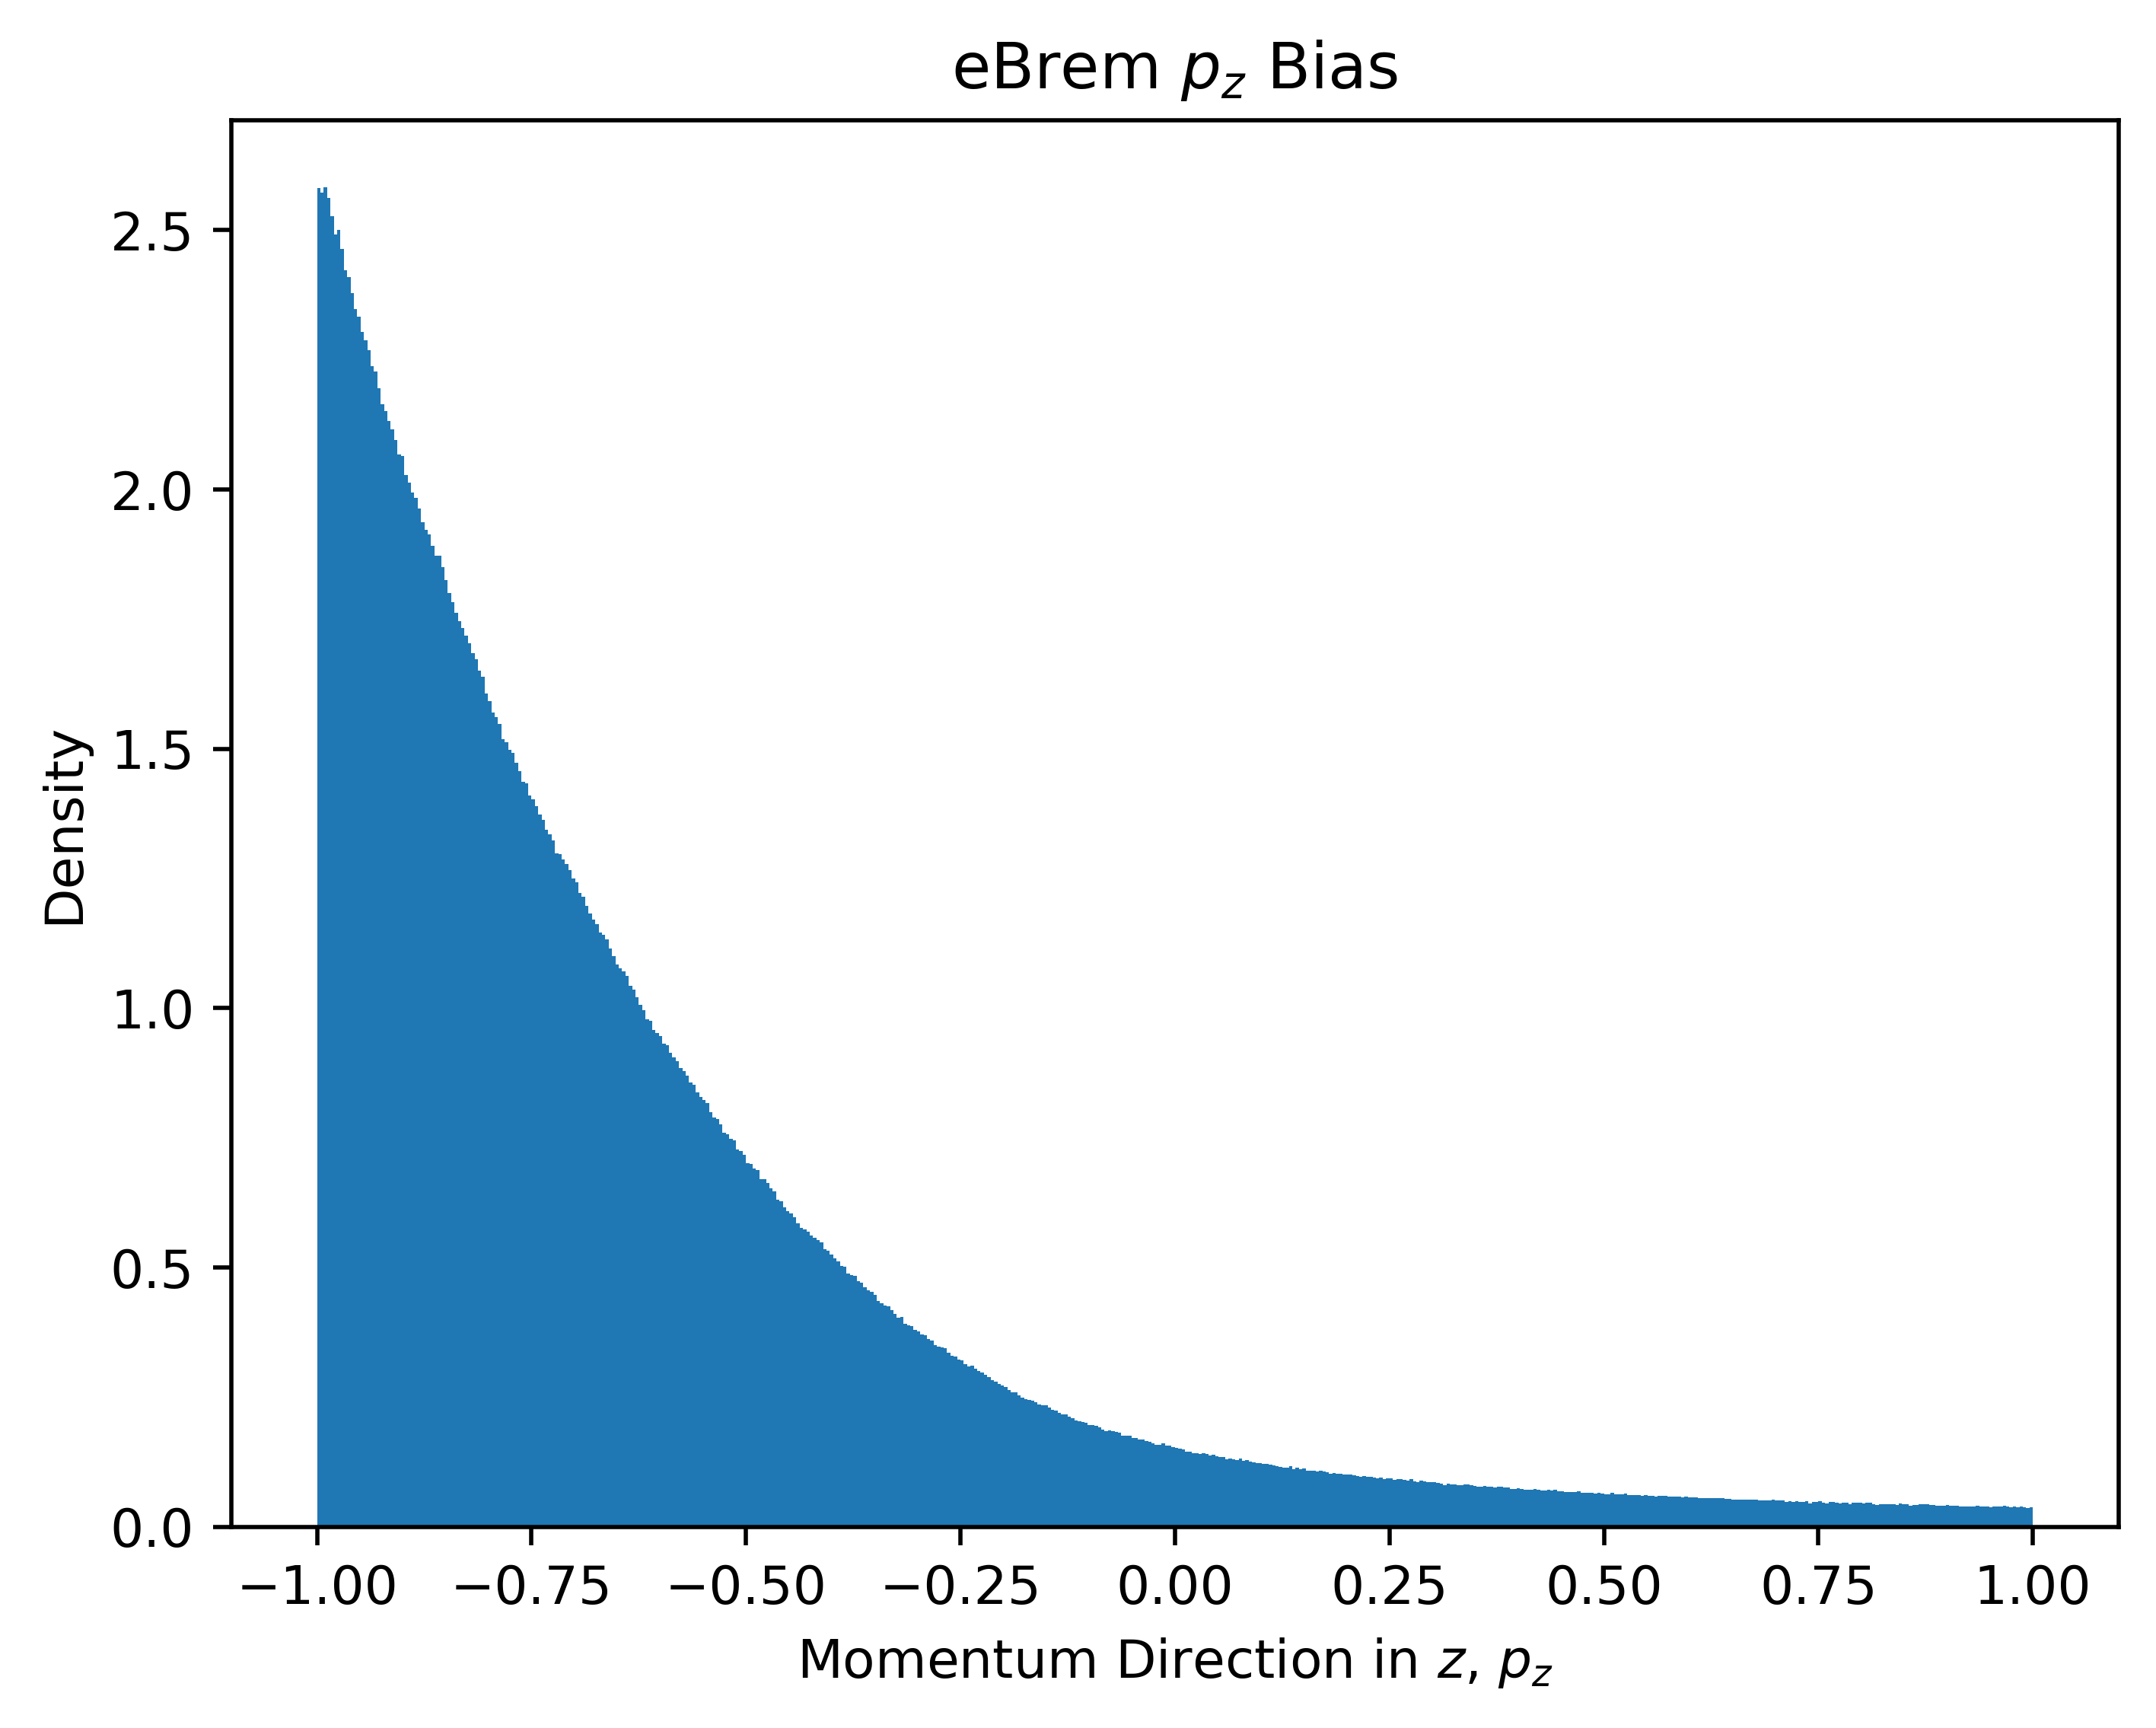

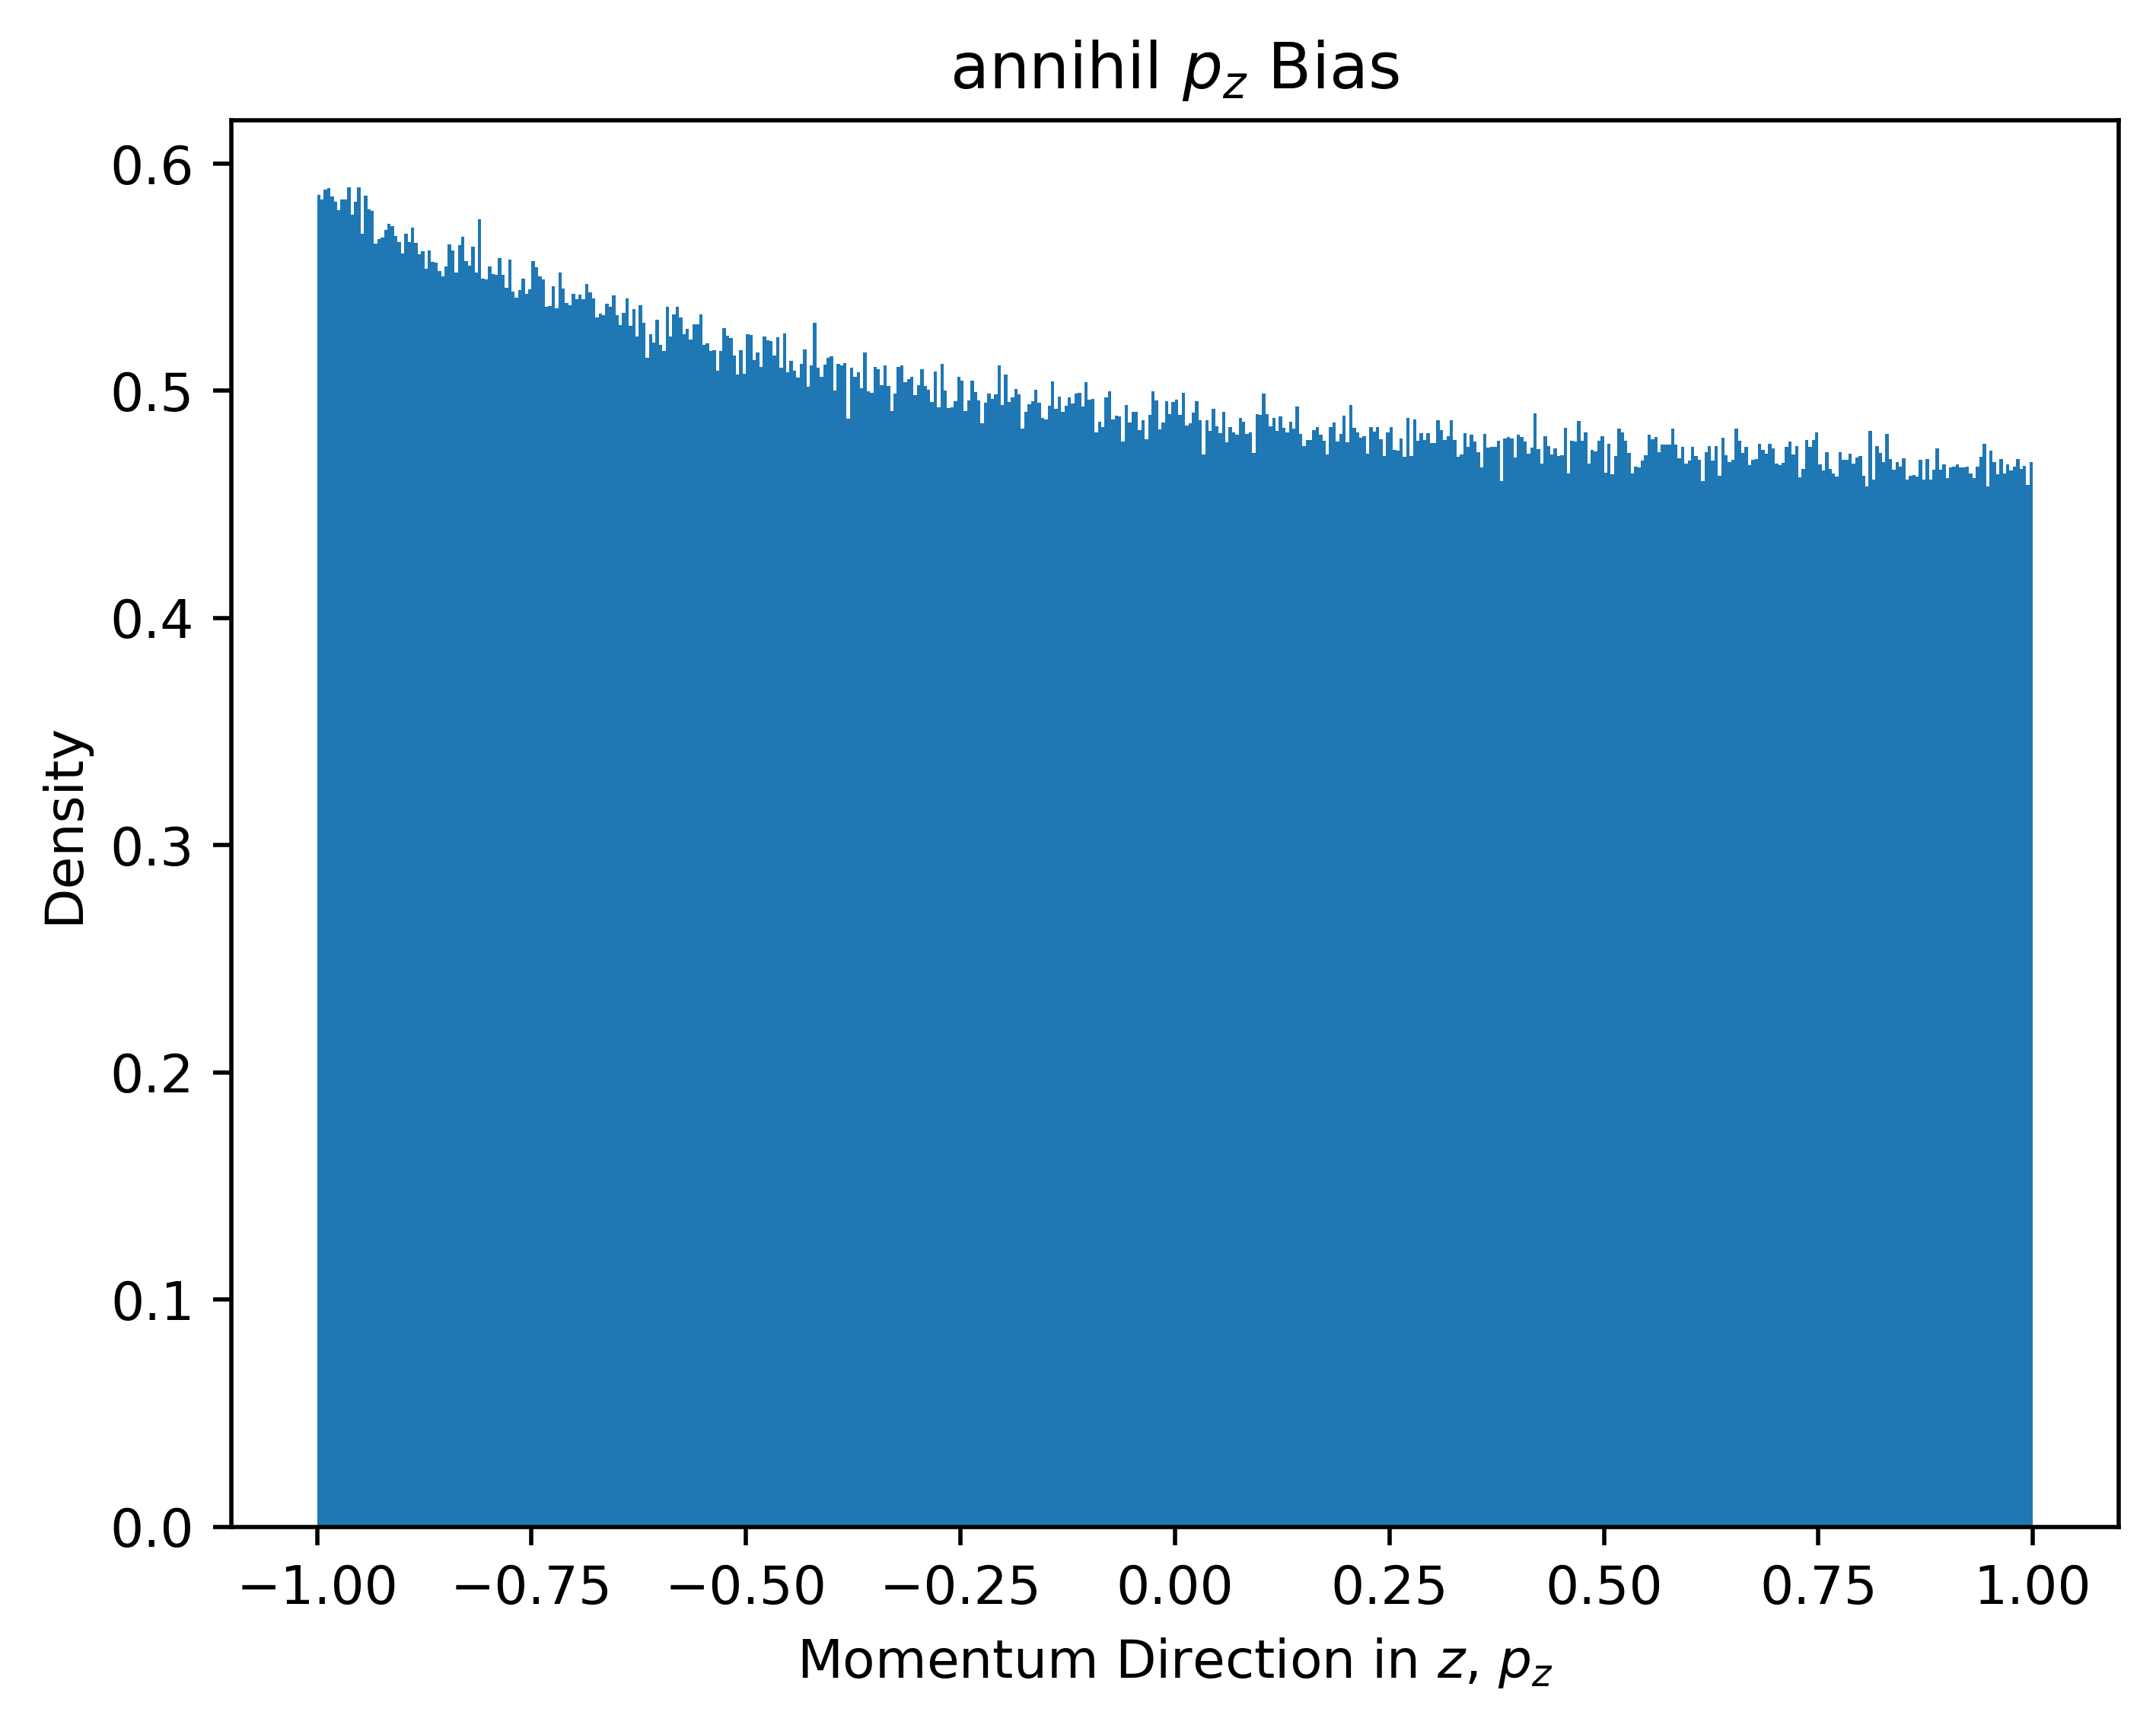

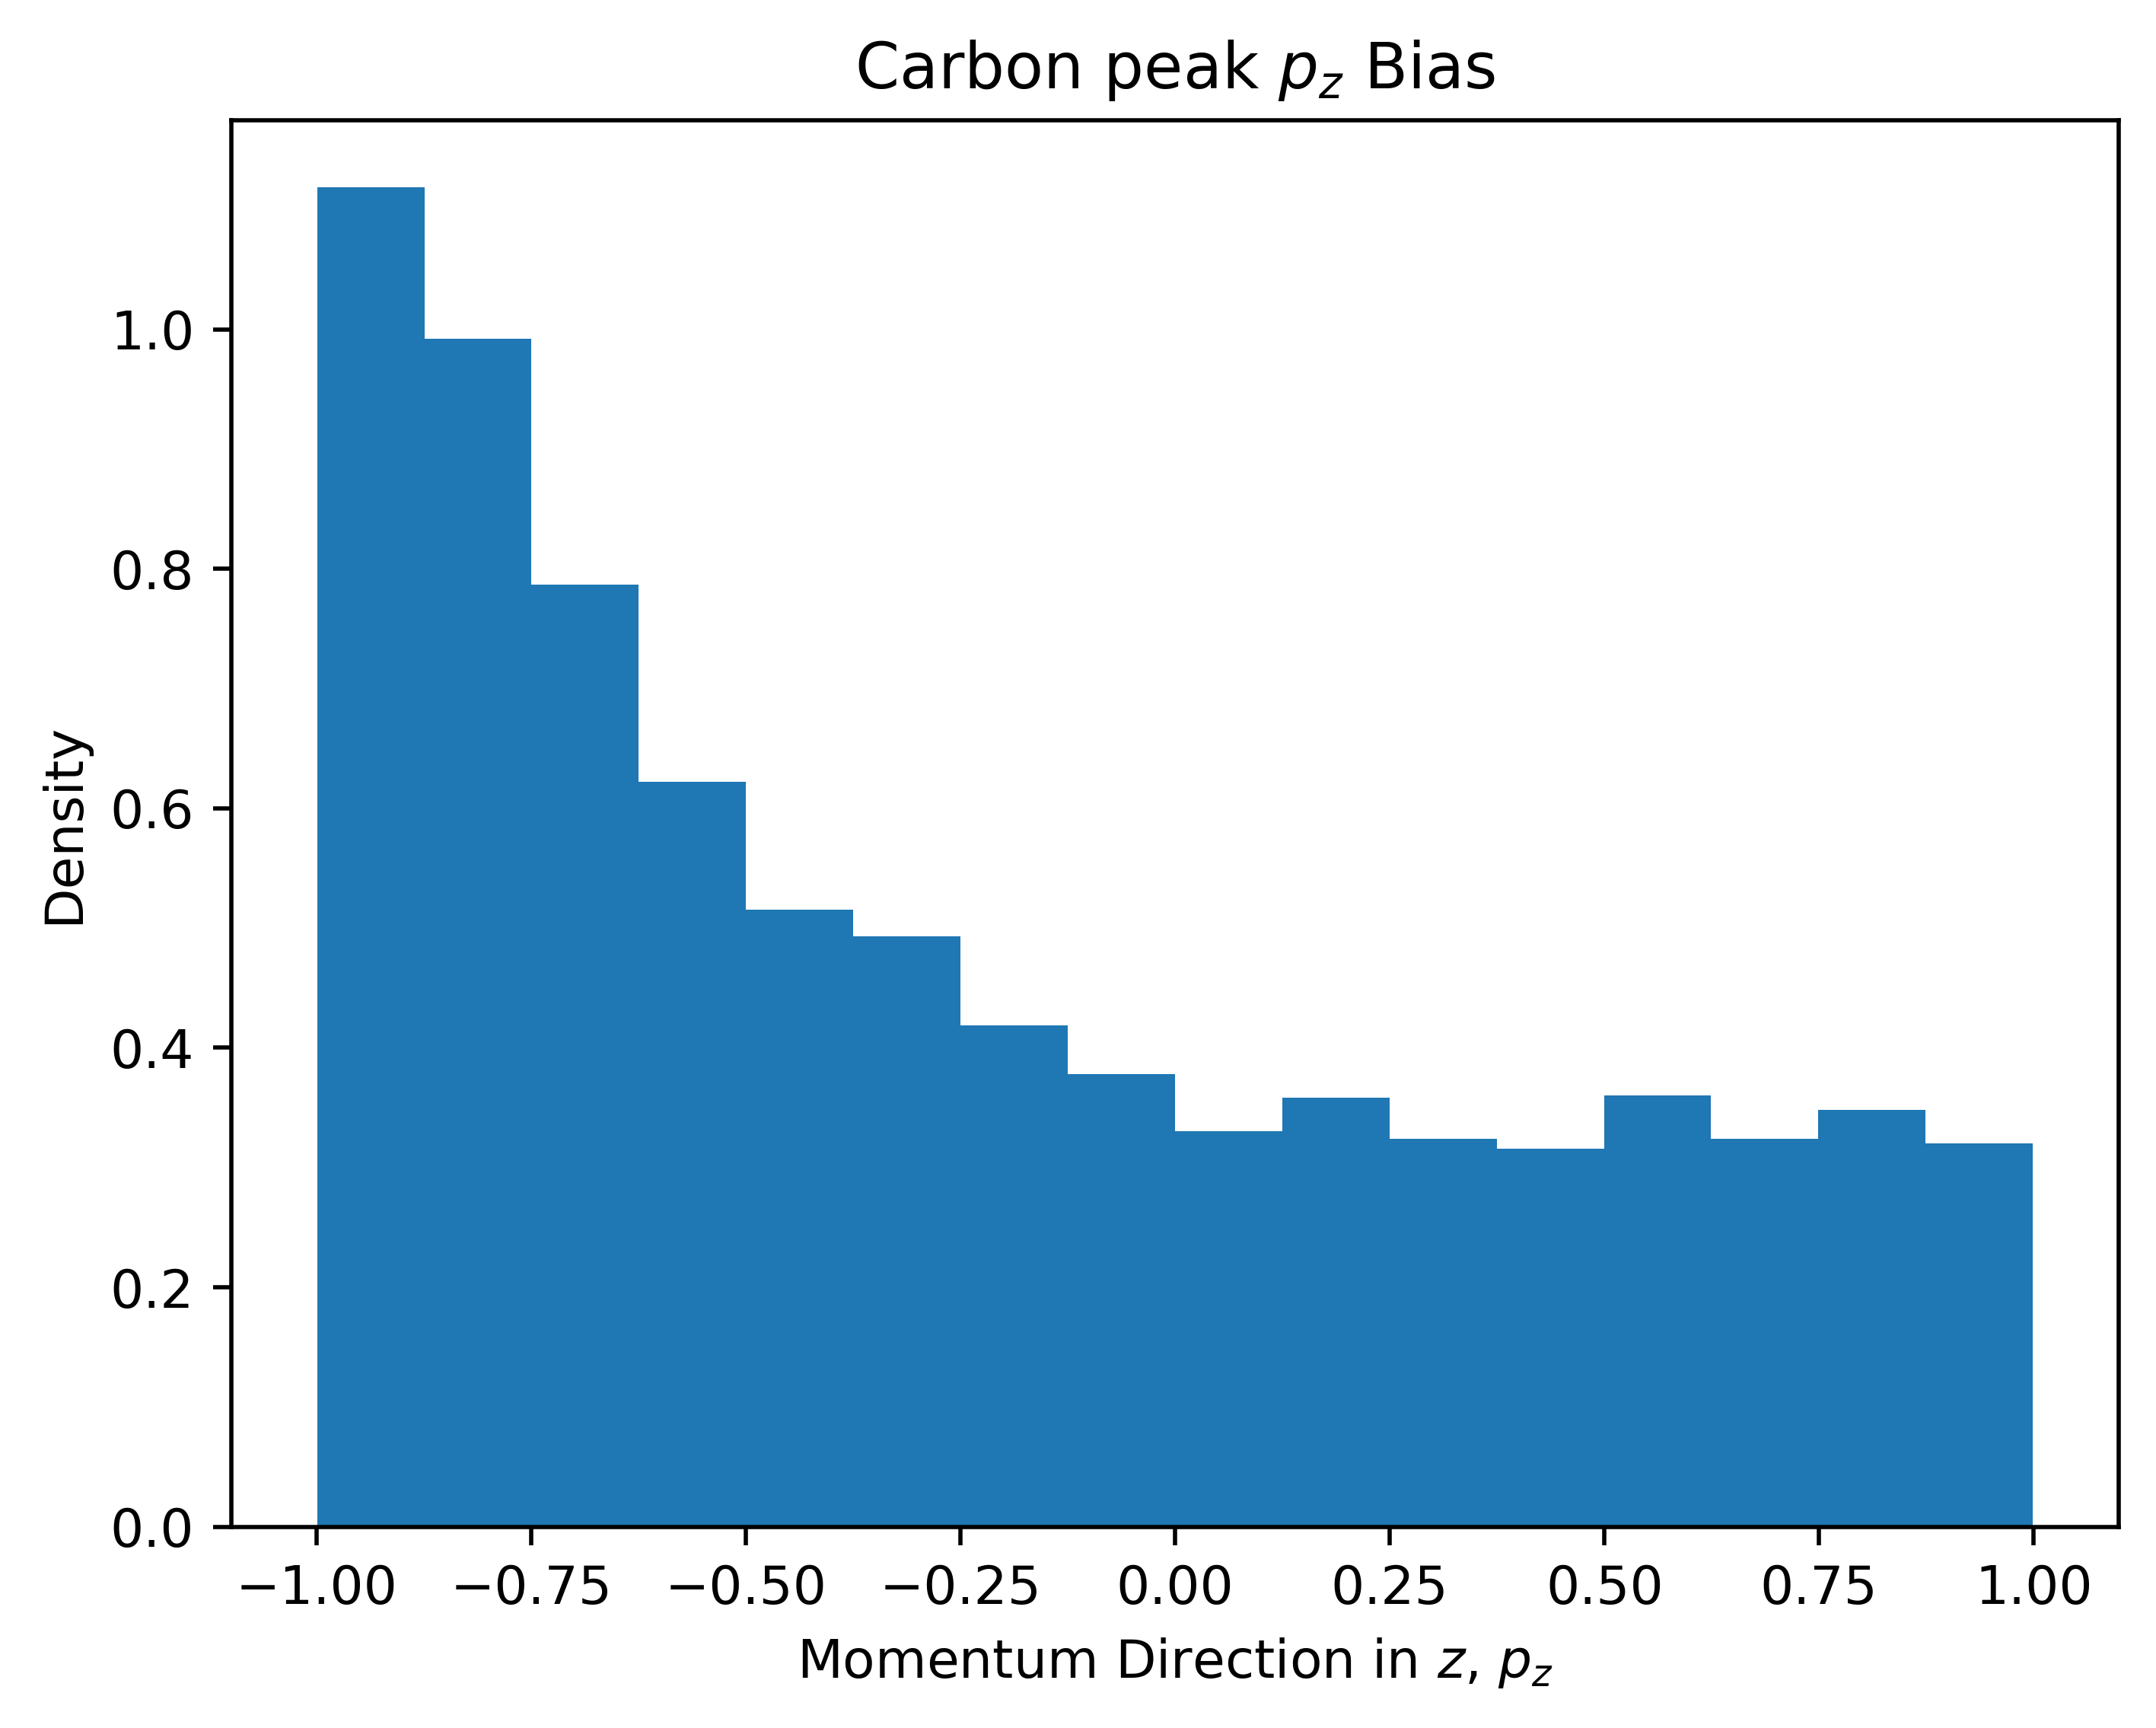

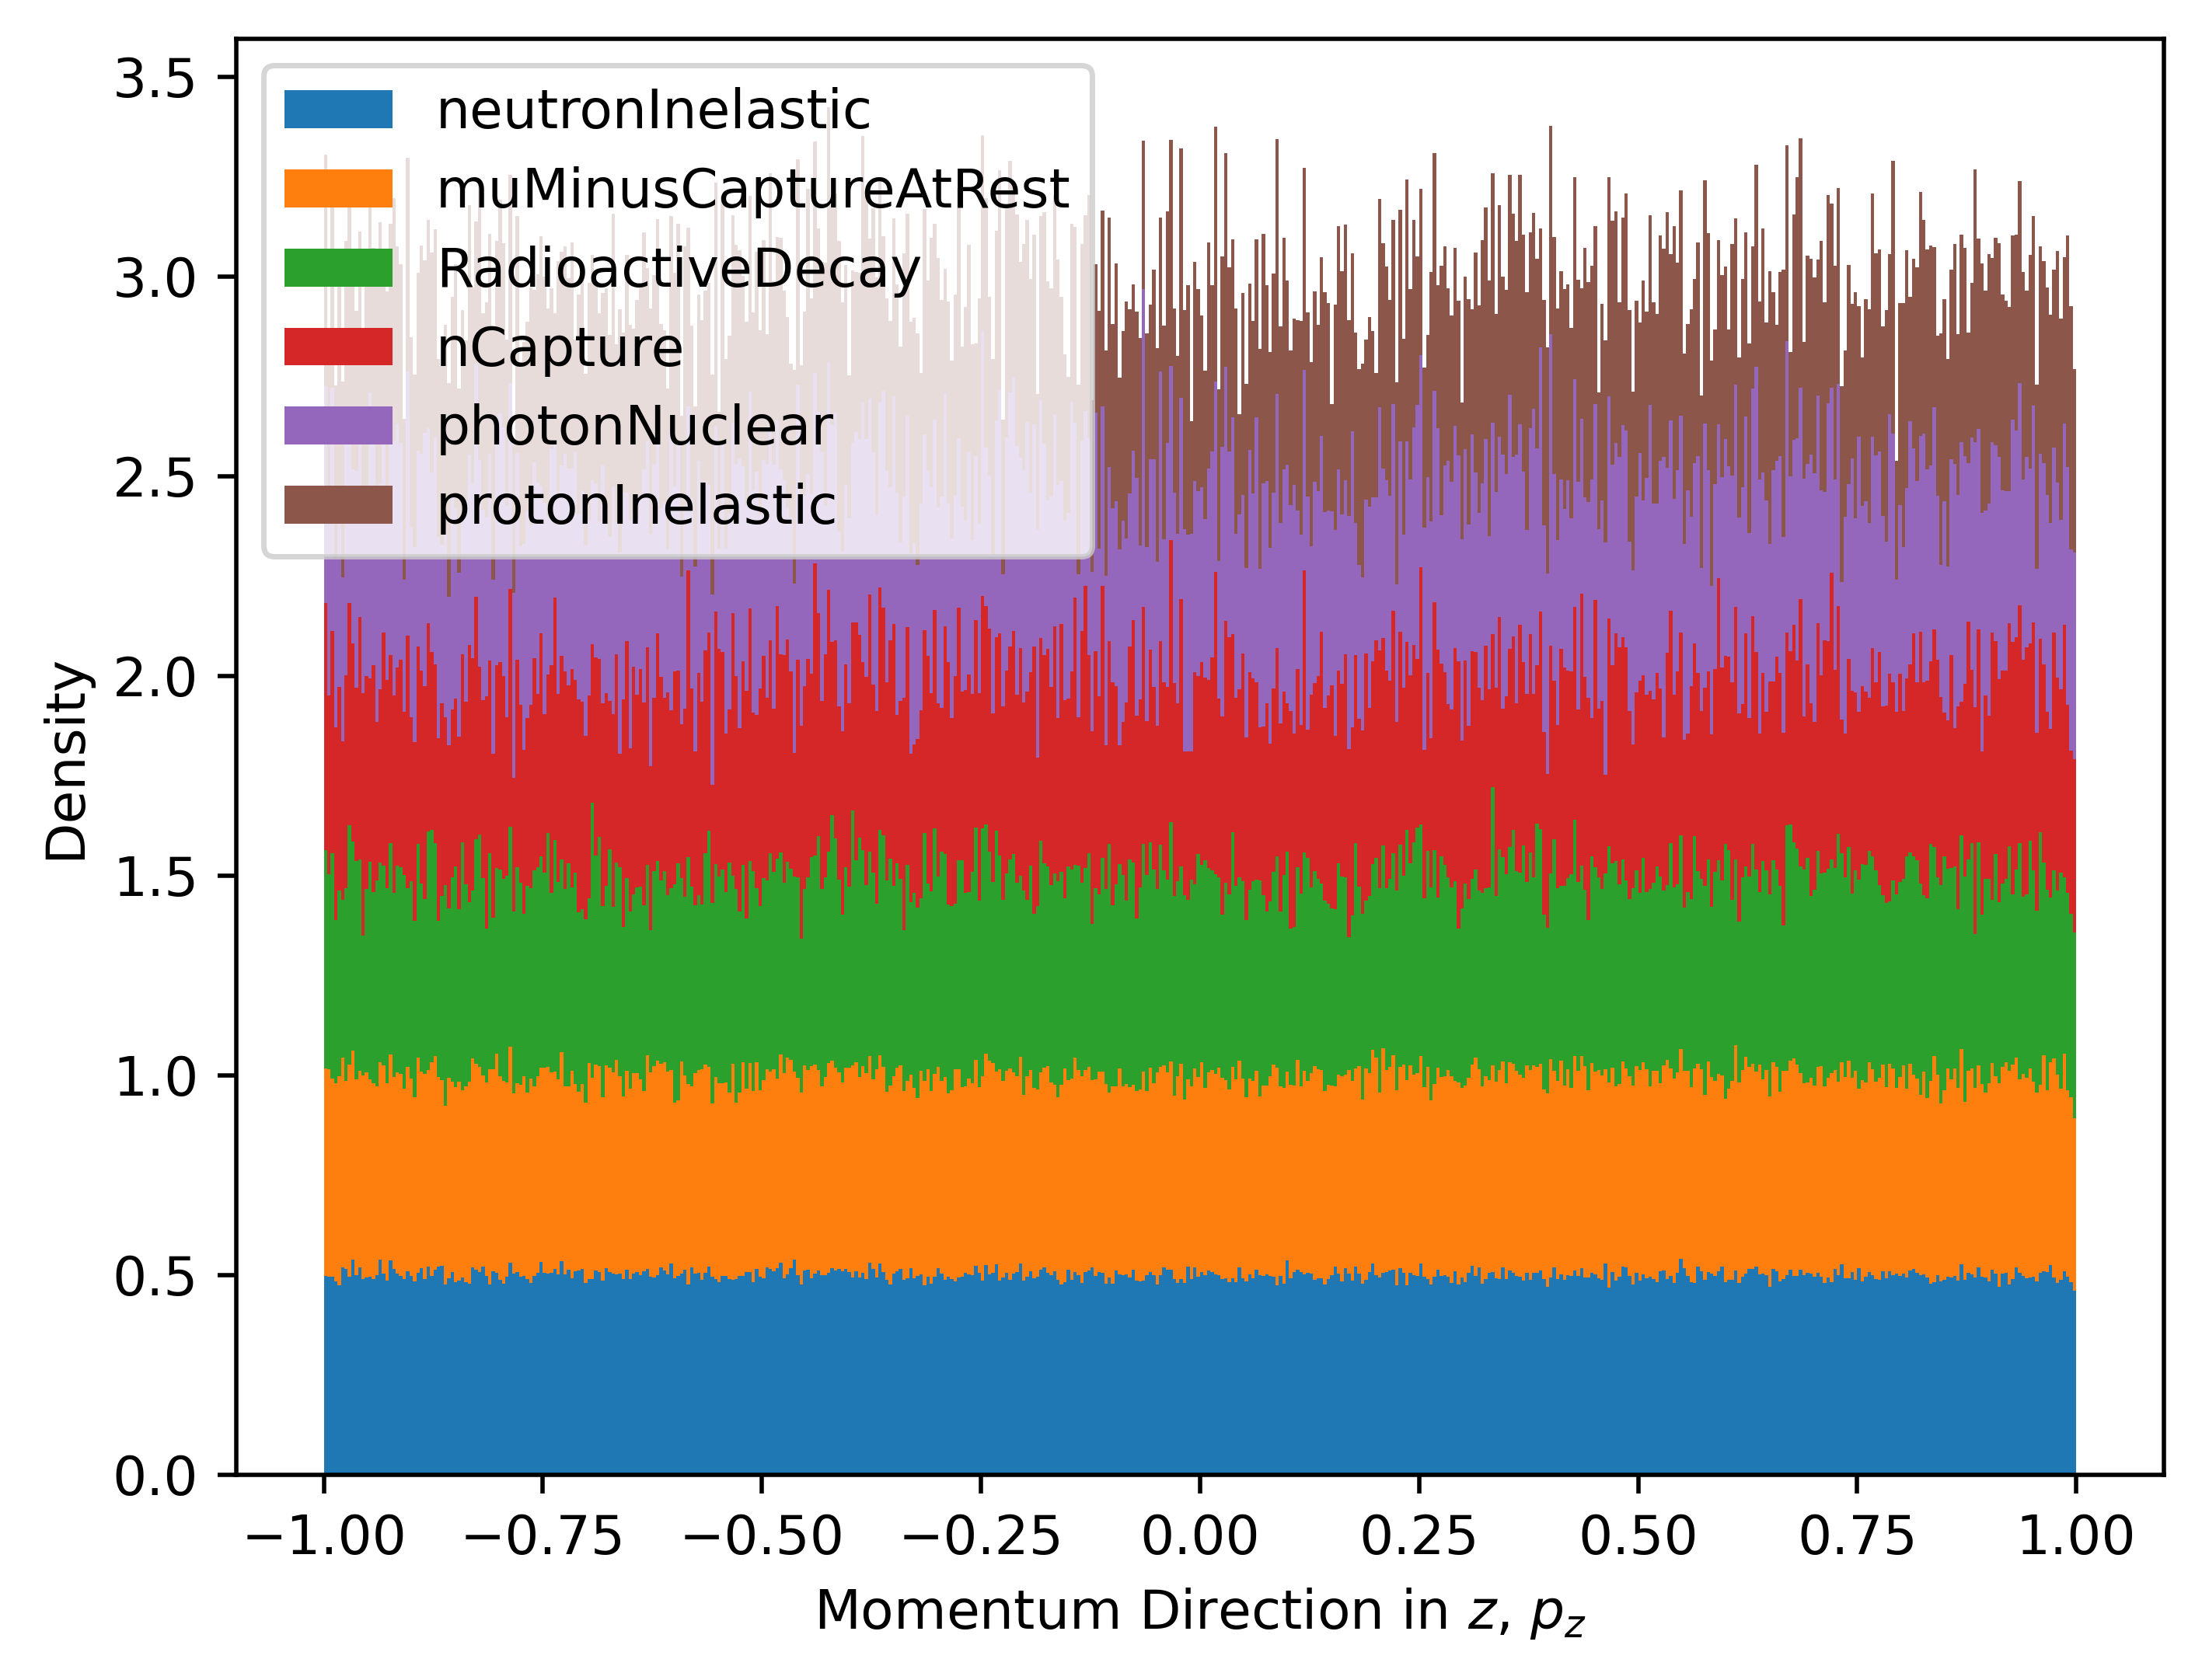

In [15]:
plot_with_peaks(
    df[include_processes(["eBrem"])]["p_z"],
    512,
    xlabel="Momentum Direction in $z$, $p_z$",
    title="eBrem $p_z$ Bias",
)
plot_with_peaks(
    df[include_processes(["annihil"])]["p_z"],
    512,
    xlabel="Momentum Direction in $z$, $p_z$",
    title="annihil $p_z$ Bias",
)
plot_with_peaks(
    df[energy_range(4.437, 4.439)]["p_z"],
    16,
    xlabel="Momentum Direction in $z$, $p_z$",
    title="Carbon peak $p_z$ Bias",
)
plot_with_peaks(
    [df[include_processes([name])]["p_z"] for name in process_names[2:8]],
    512,
    xlabel="Momentum Direction in $z$, $p_z$",
    stacked=True,
    legend=process_names[2:8],
    bin_range=(-1.0, 1.0),
)

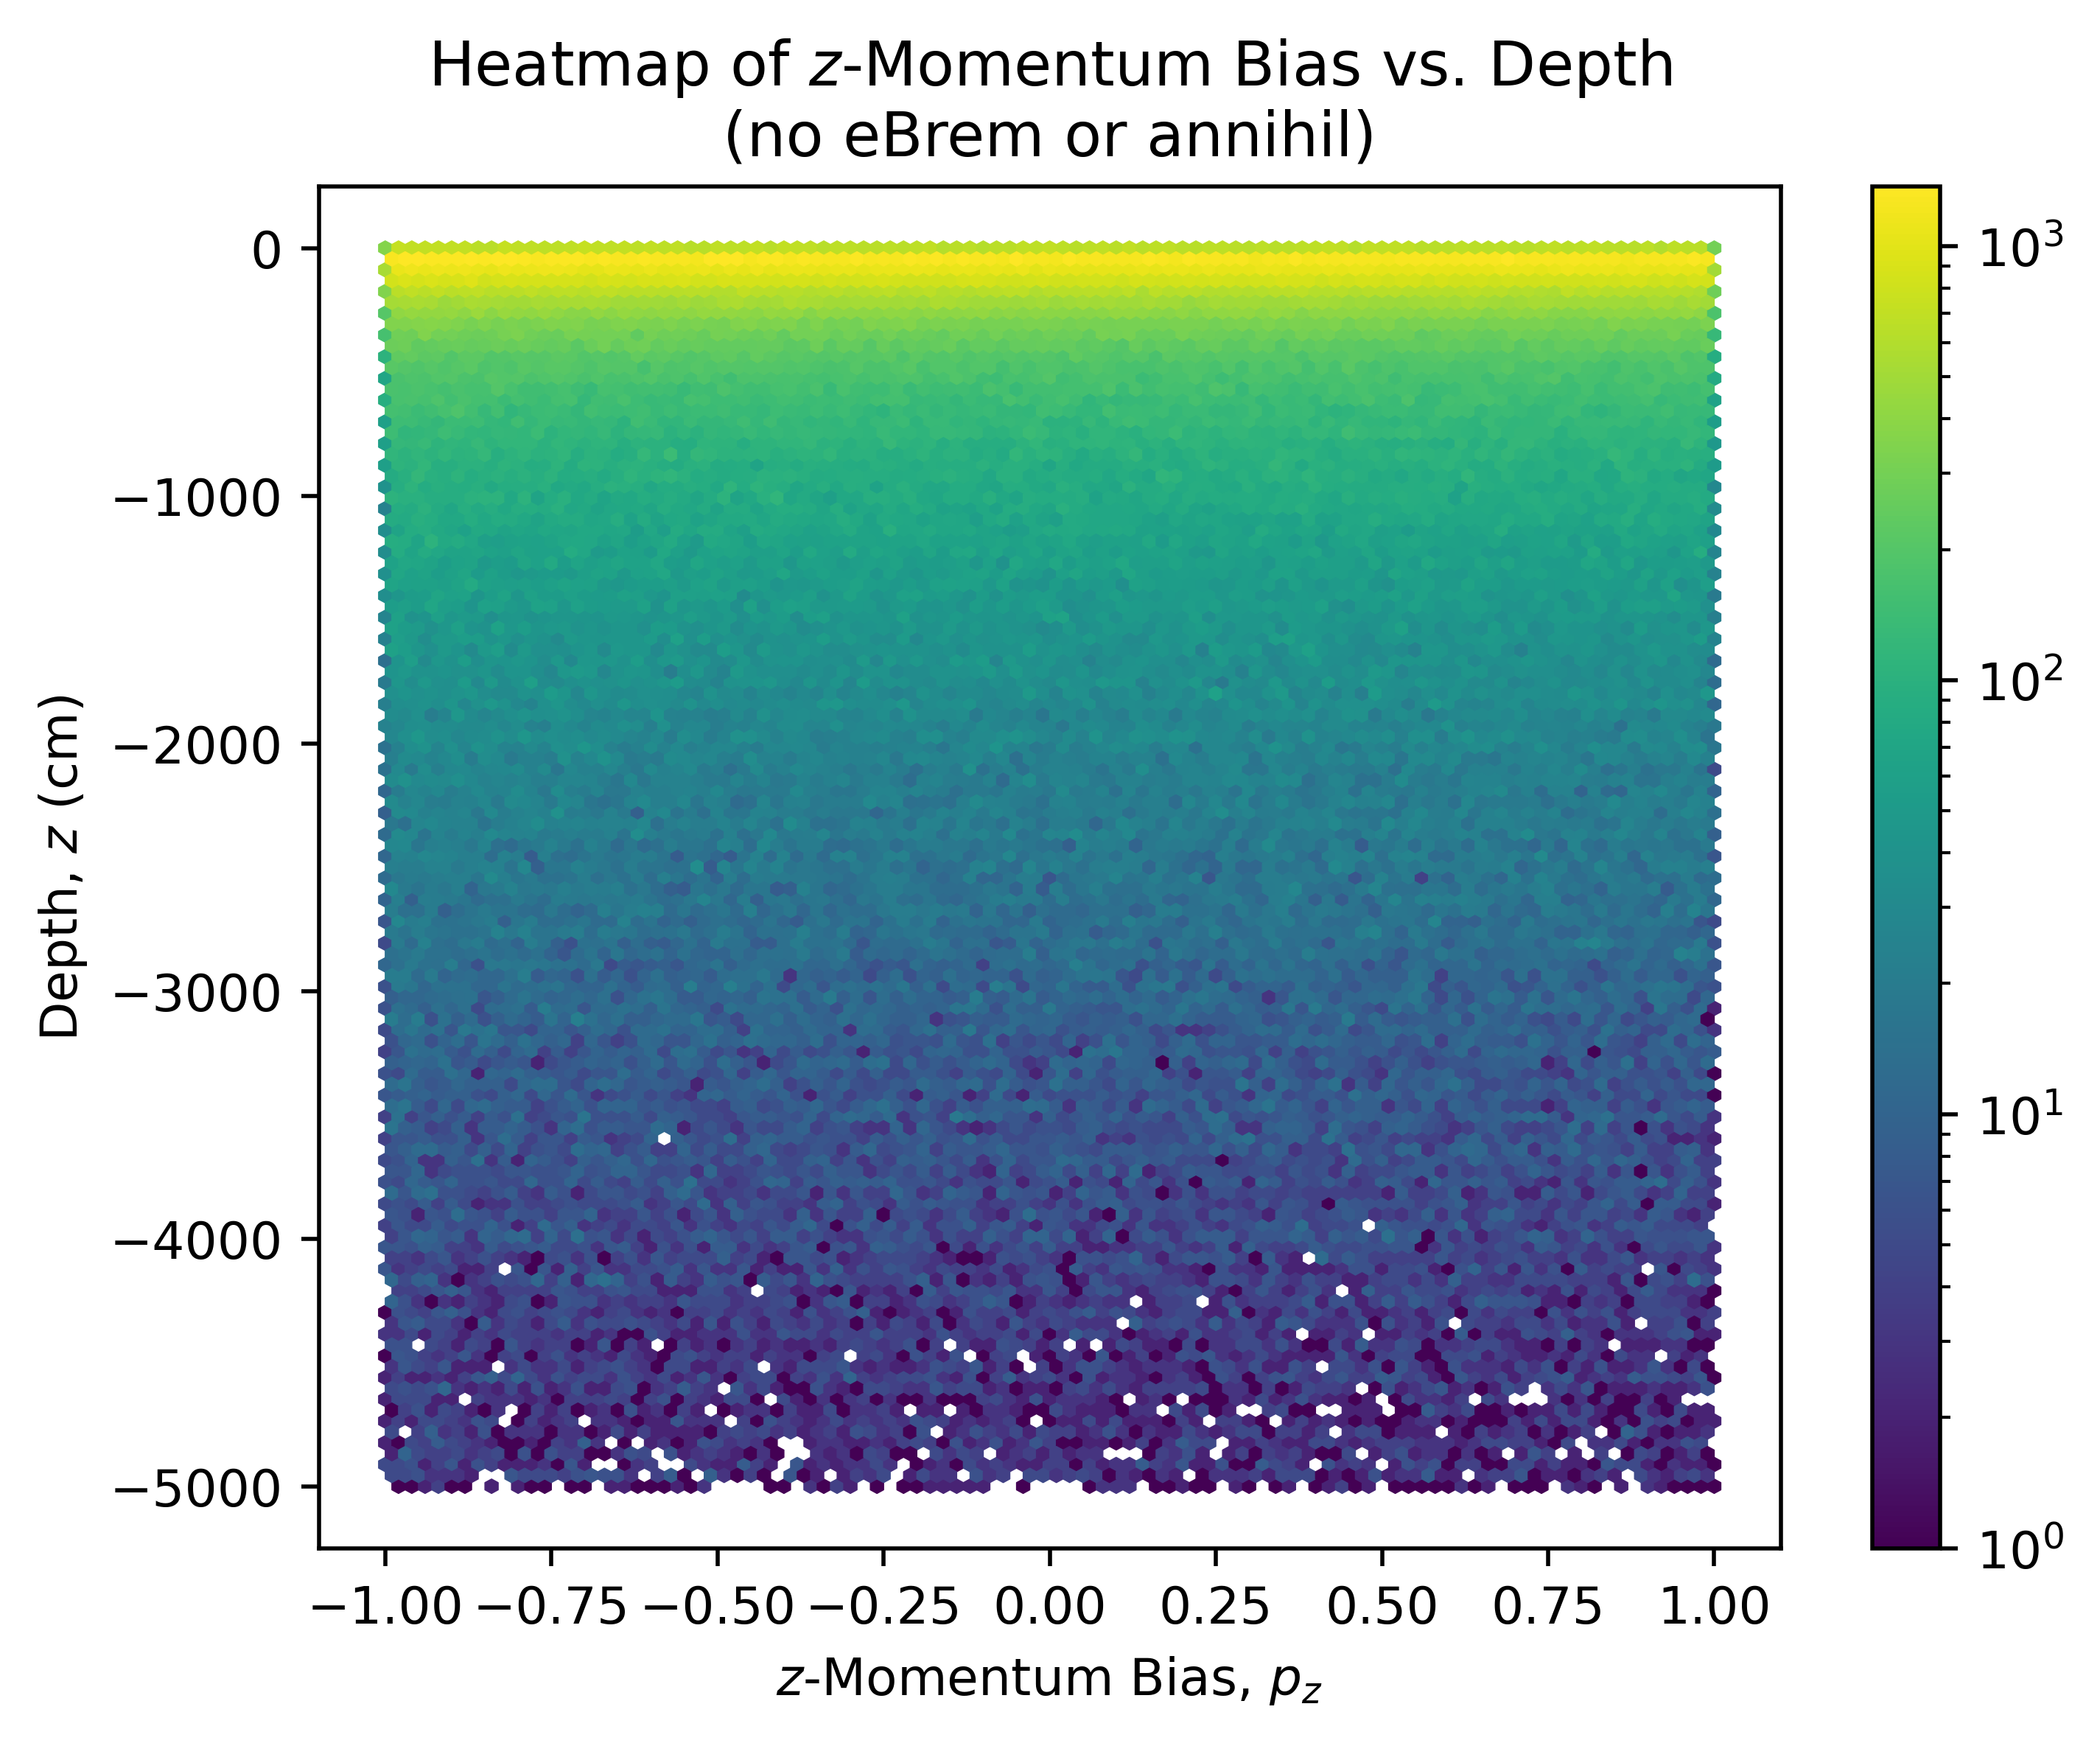

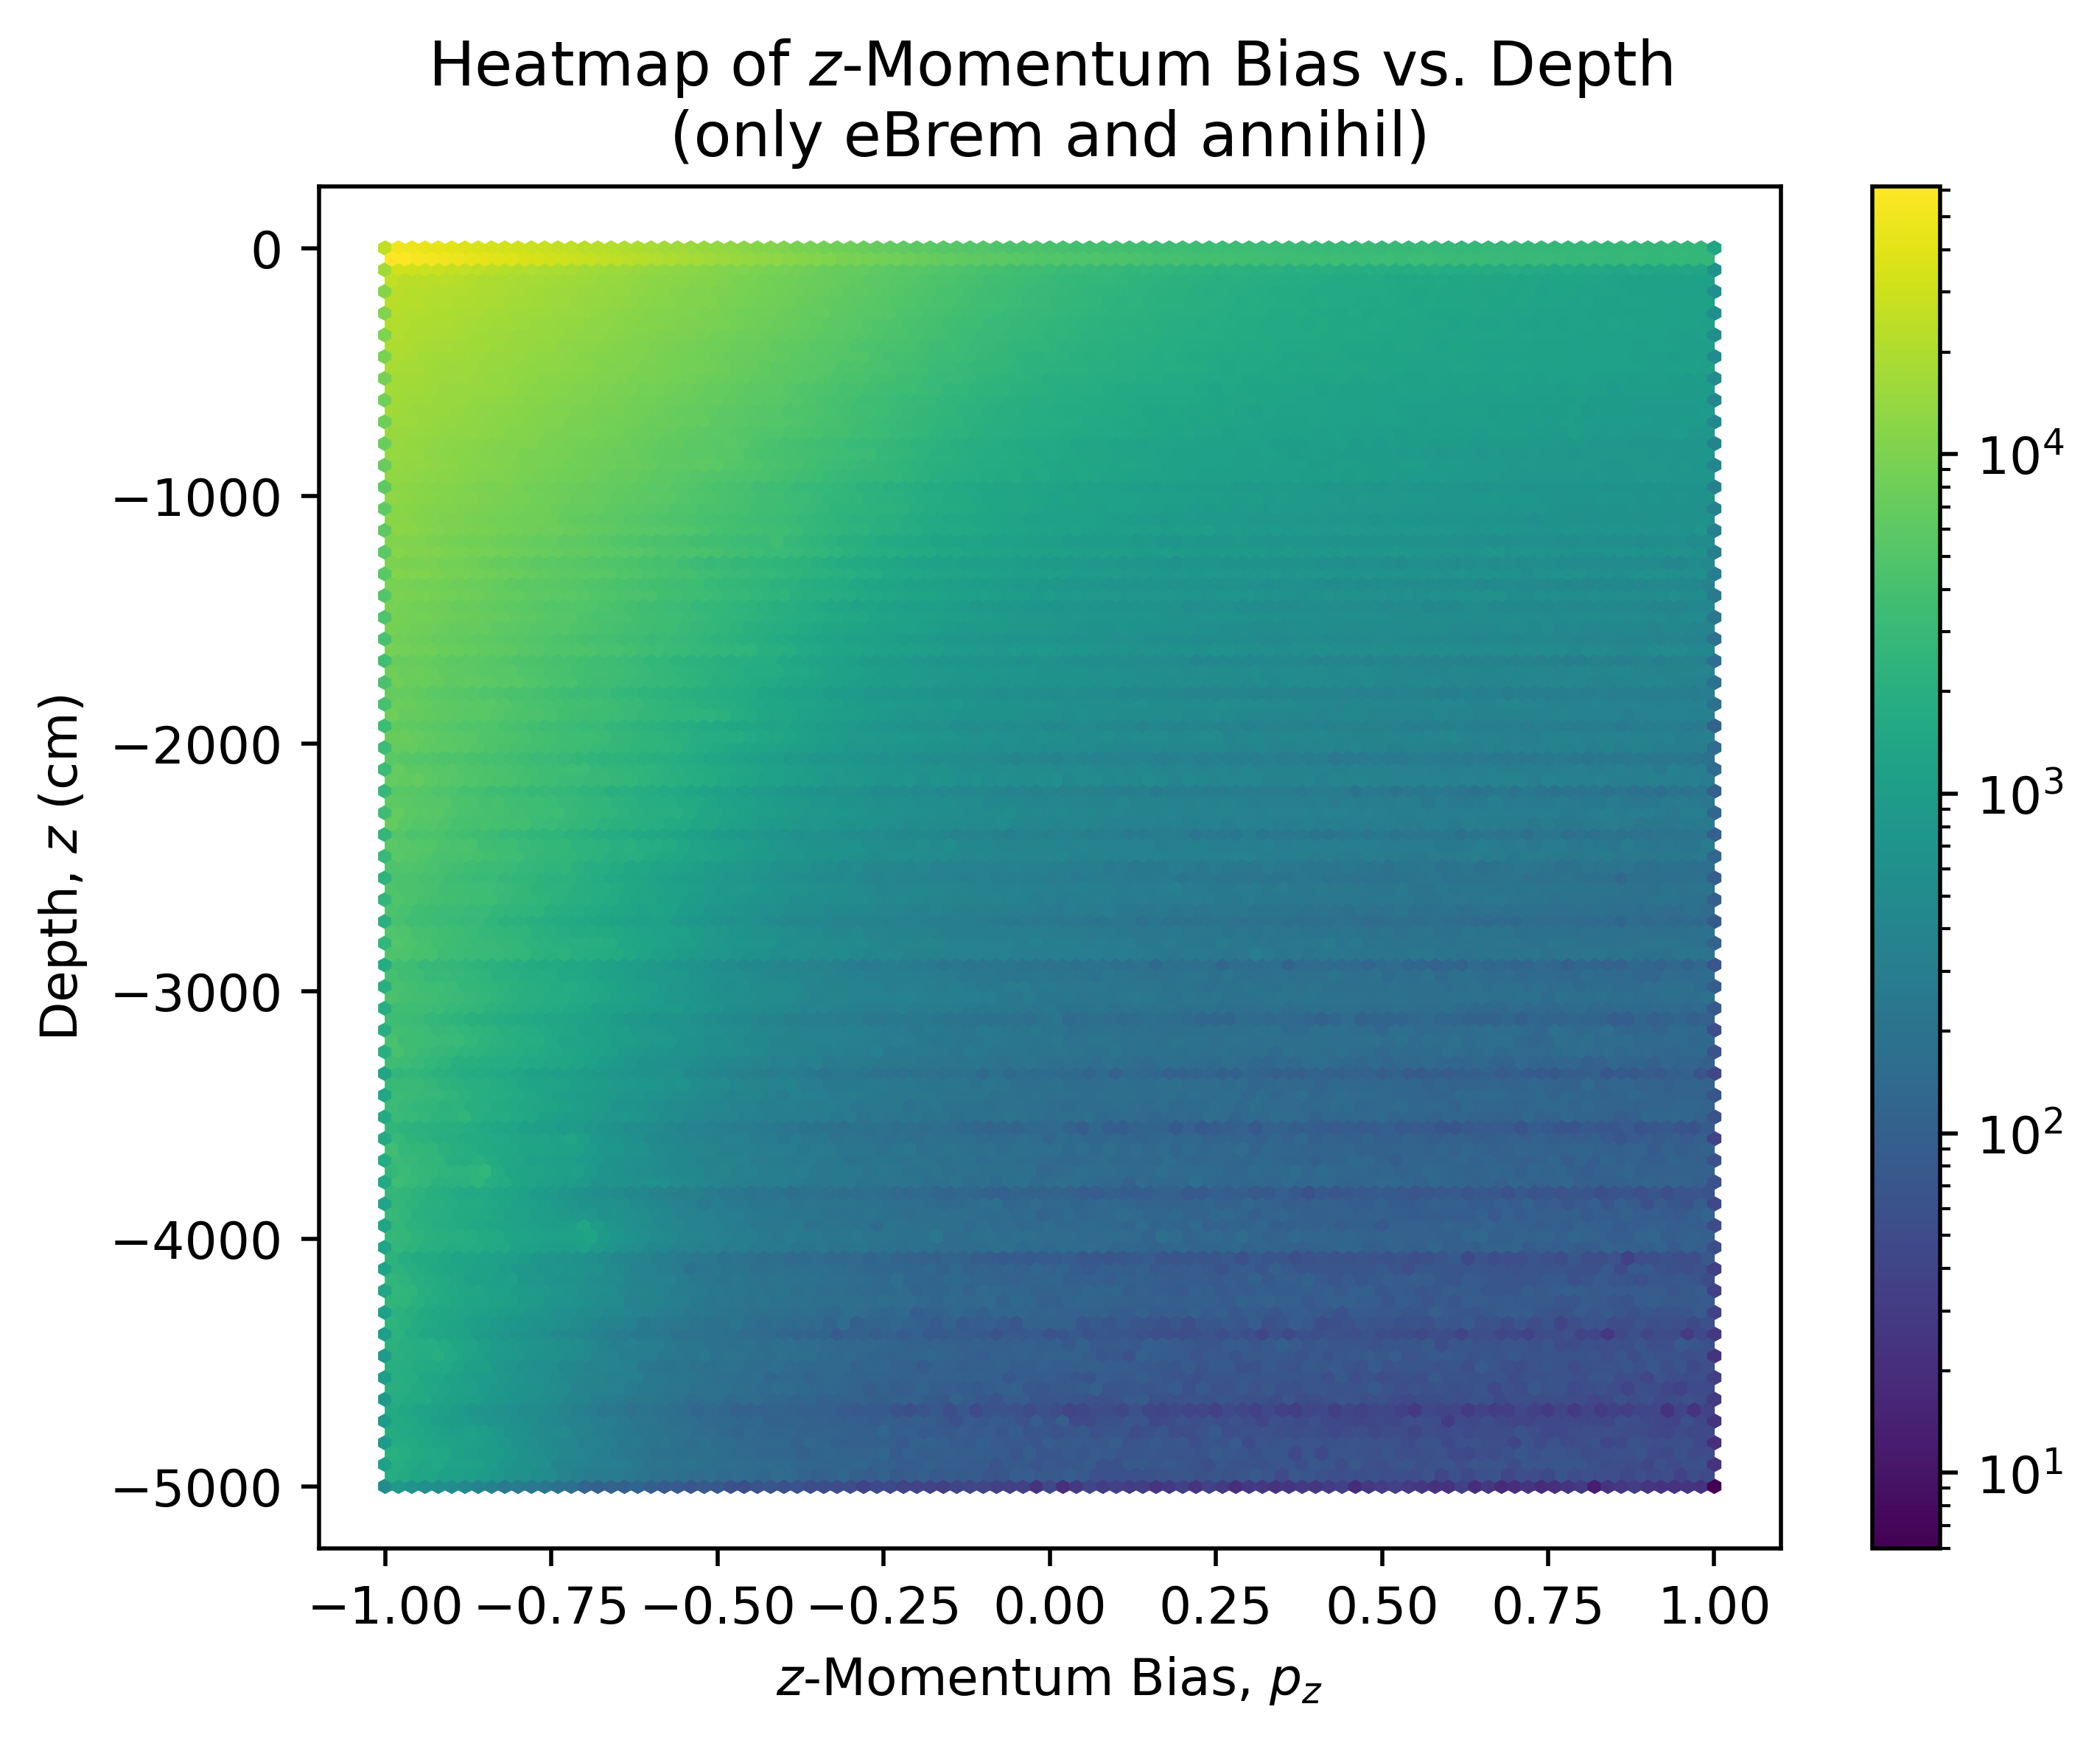

In [16]:
heatmap, x_edges, y_edges = np.histogram2d(df["p_z"], df["z"] / 10.0, bins=10)
extent = (x_edges[0], x_edges[-1], y_edges[0], y_edges[-1])
e_range = df["E"].between(2.0, 7.0)
isotropic = exclude_processes(["eBrem", "annihil"])
anisotropic = include_processes(["eBrem", "annihil"])

plt.hexbin(
    df[isotropic]["p_z"], df[isotropic]["z"] / 10.0, linewidths=0.2, norm=LogNorm()
)
plt.colorbar()
plt.xlabel("$z$-Momentum Bias, $p_z$")
plt.ylabel("Depth, $z$ (cm)")
plt.title("Heatmap of $z$-Momentum Bias vs. Depth\n(no eBrem or annihil)")
plt.show()

plt.hexbin(
    df[anisotropic]["p_z"], df[anisotropic]["z"] / 10.0, linewidths=0.2, norm=LogNorm()
)
plt.colorbar()
plt.xlabel("$z$-Momentum Bias, $p_z$")
plt.ylabel("Depth, $z$ (cm)")
plt.title("Heatmap of $z$-Momentum Bias vs. Depth\n(only eBrem and annihil)")
plt.show()

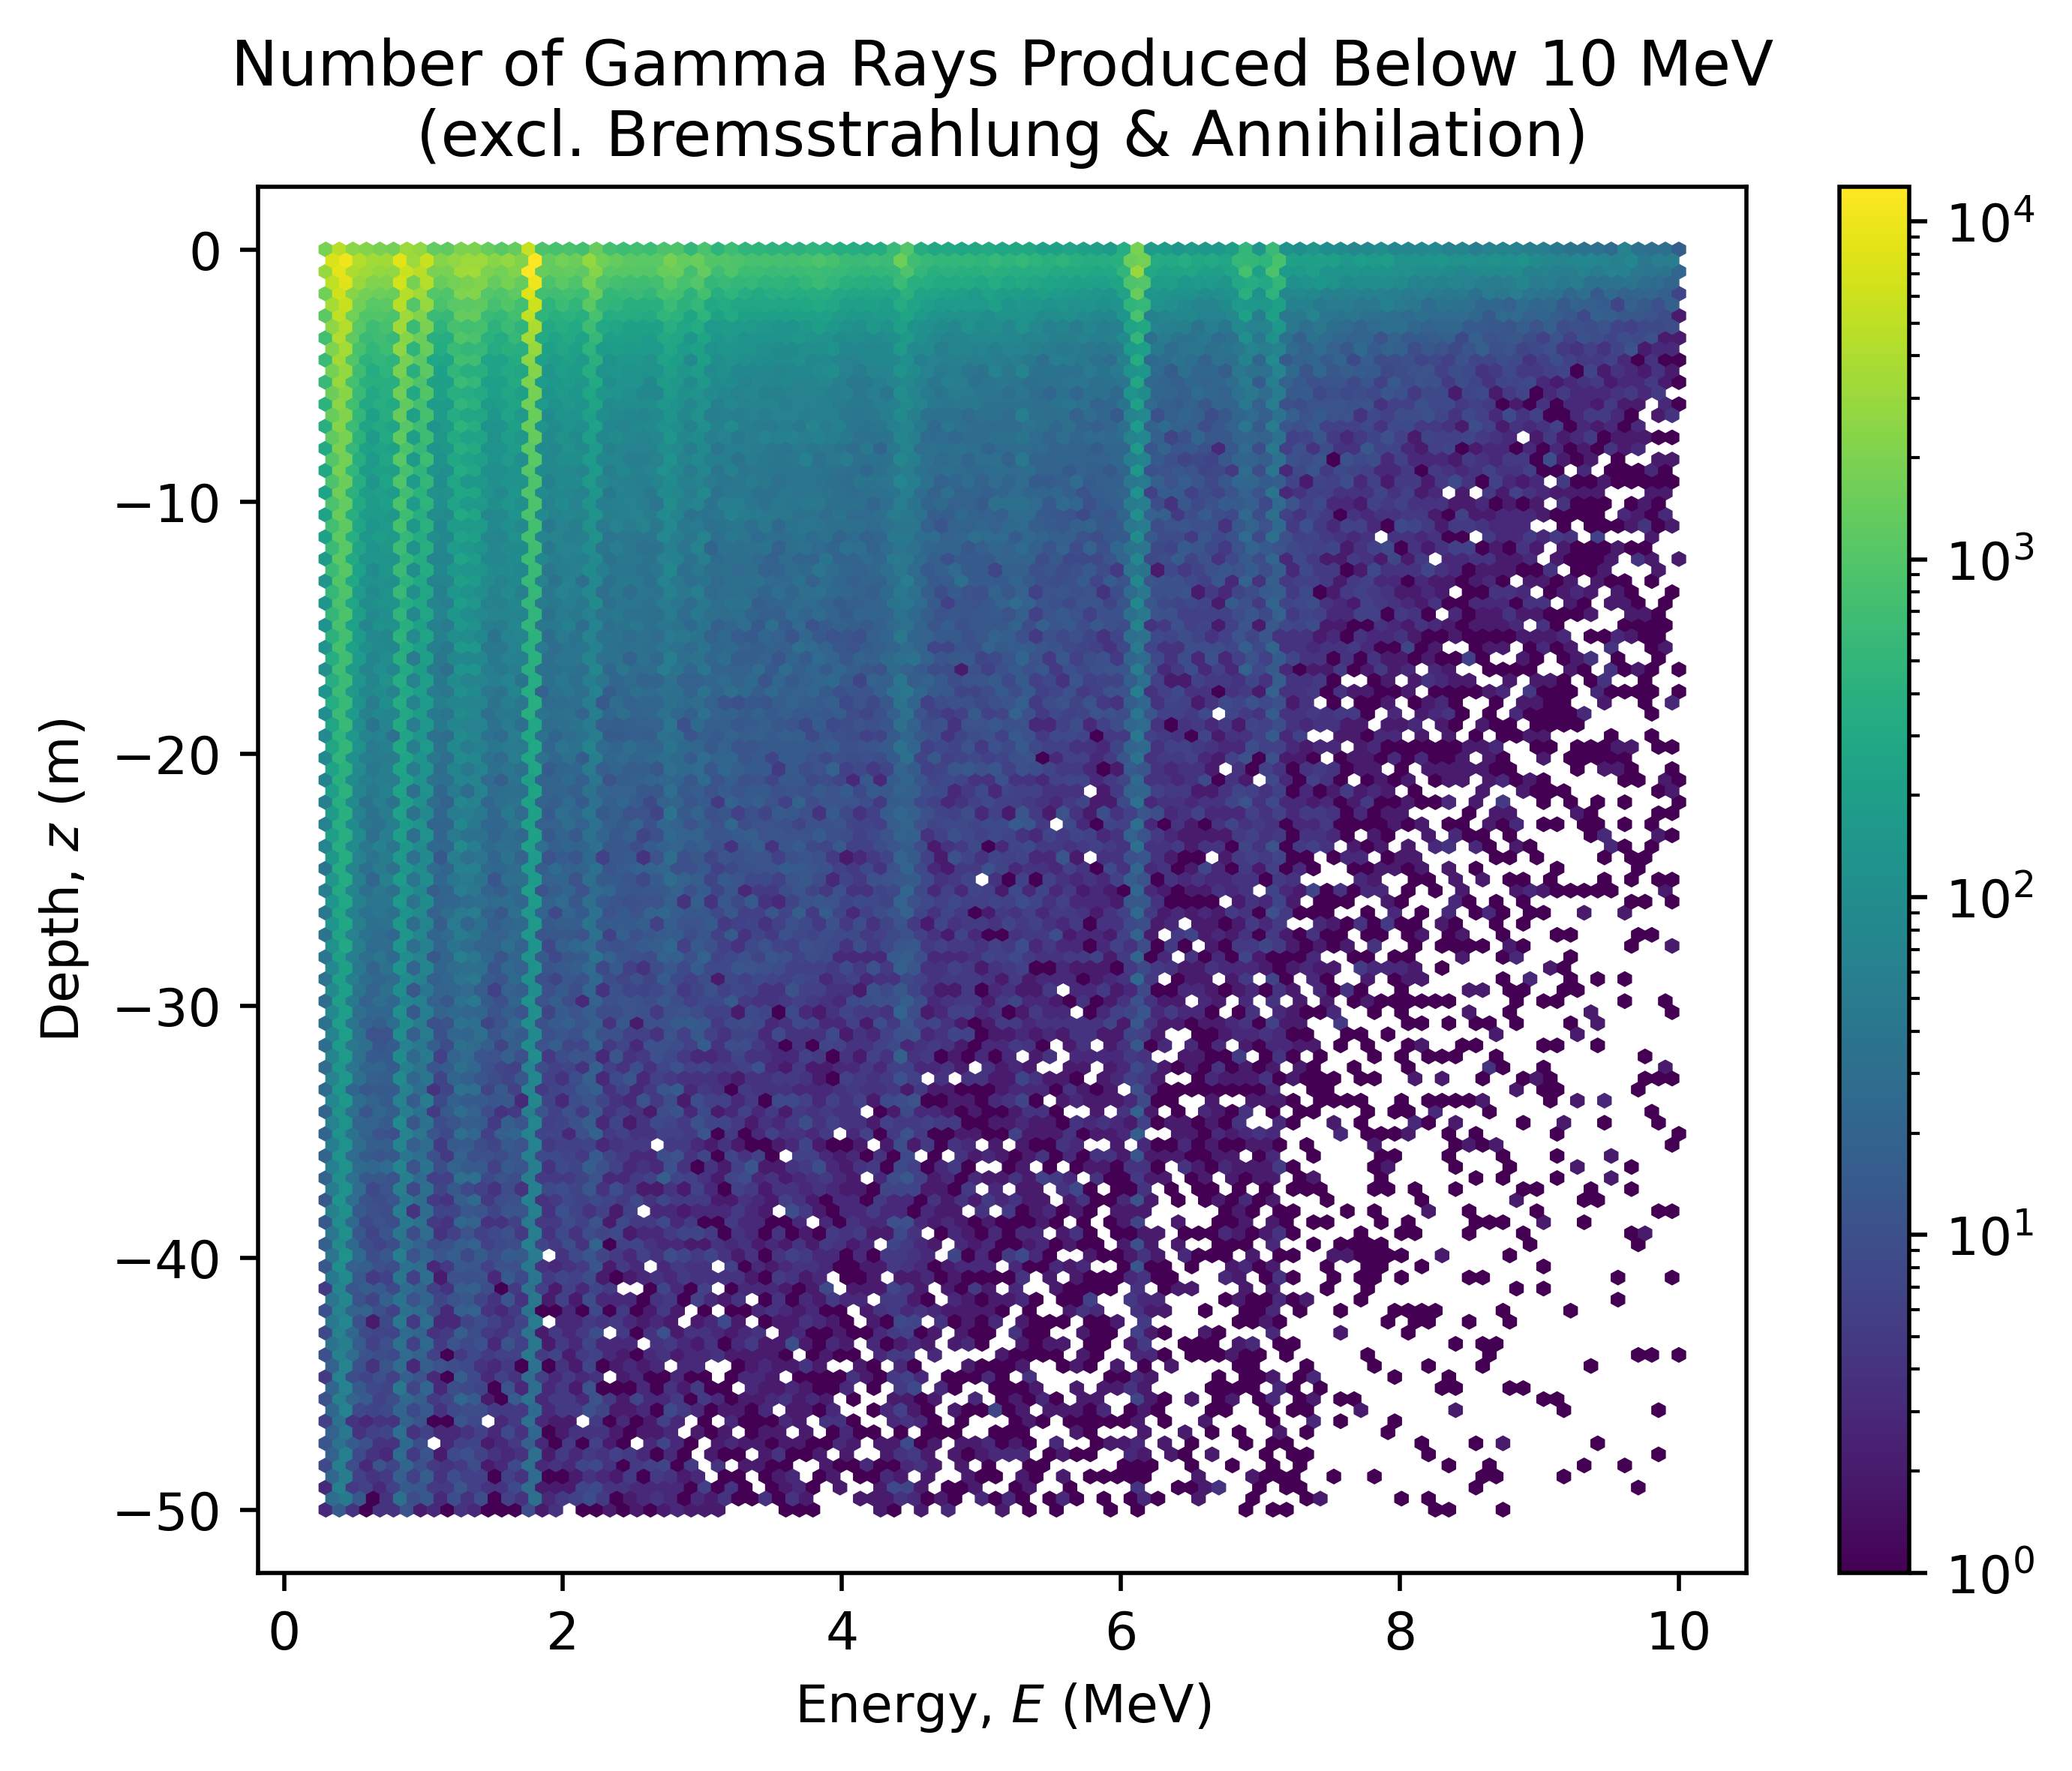

In [17]:
mask = df["E"].between(0, 10) & isotropic
plt.hexbin(df[mask]["E"], df[mask]["z"] / 1e3, linewidths=0.2, norm=LogNorm())
plt.colorbar()
plt.xlabel("Energy, $E$ (MeV)")
plt.ylabel("Depth, $z$ (m)")
plt.title(
    "Number of Gamma Rays Produced Below 10 MeV\n(excl. Bremsstrahlung & Annihilation)"
)
plt.show()

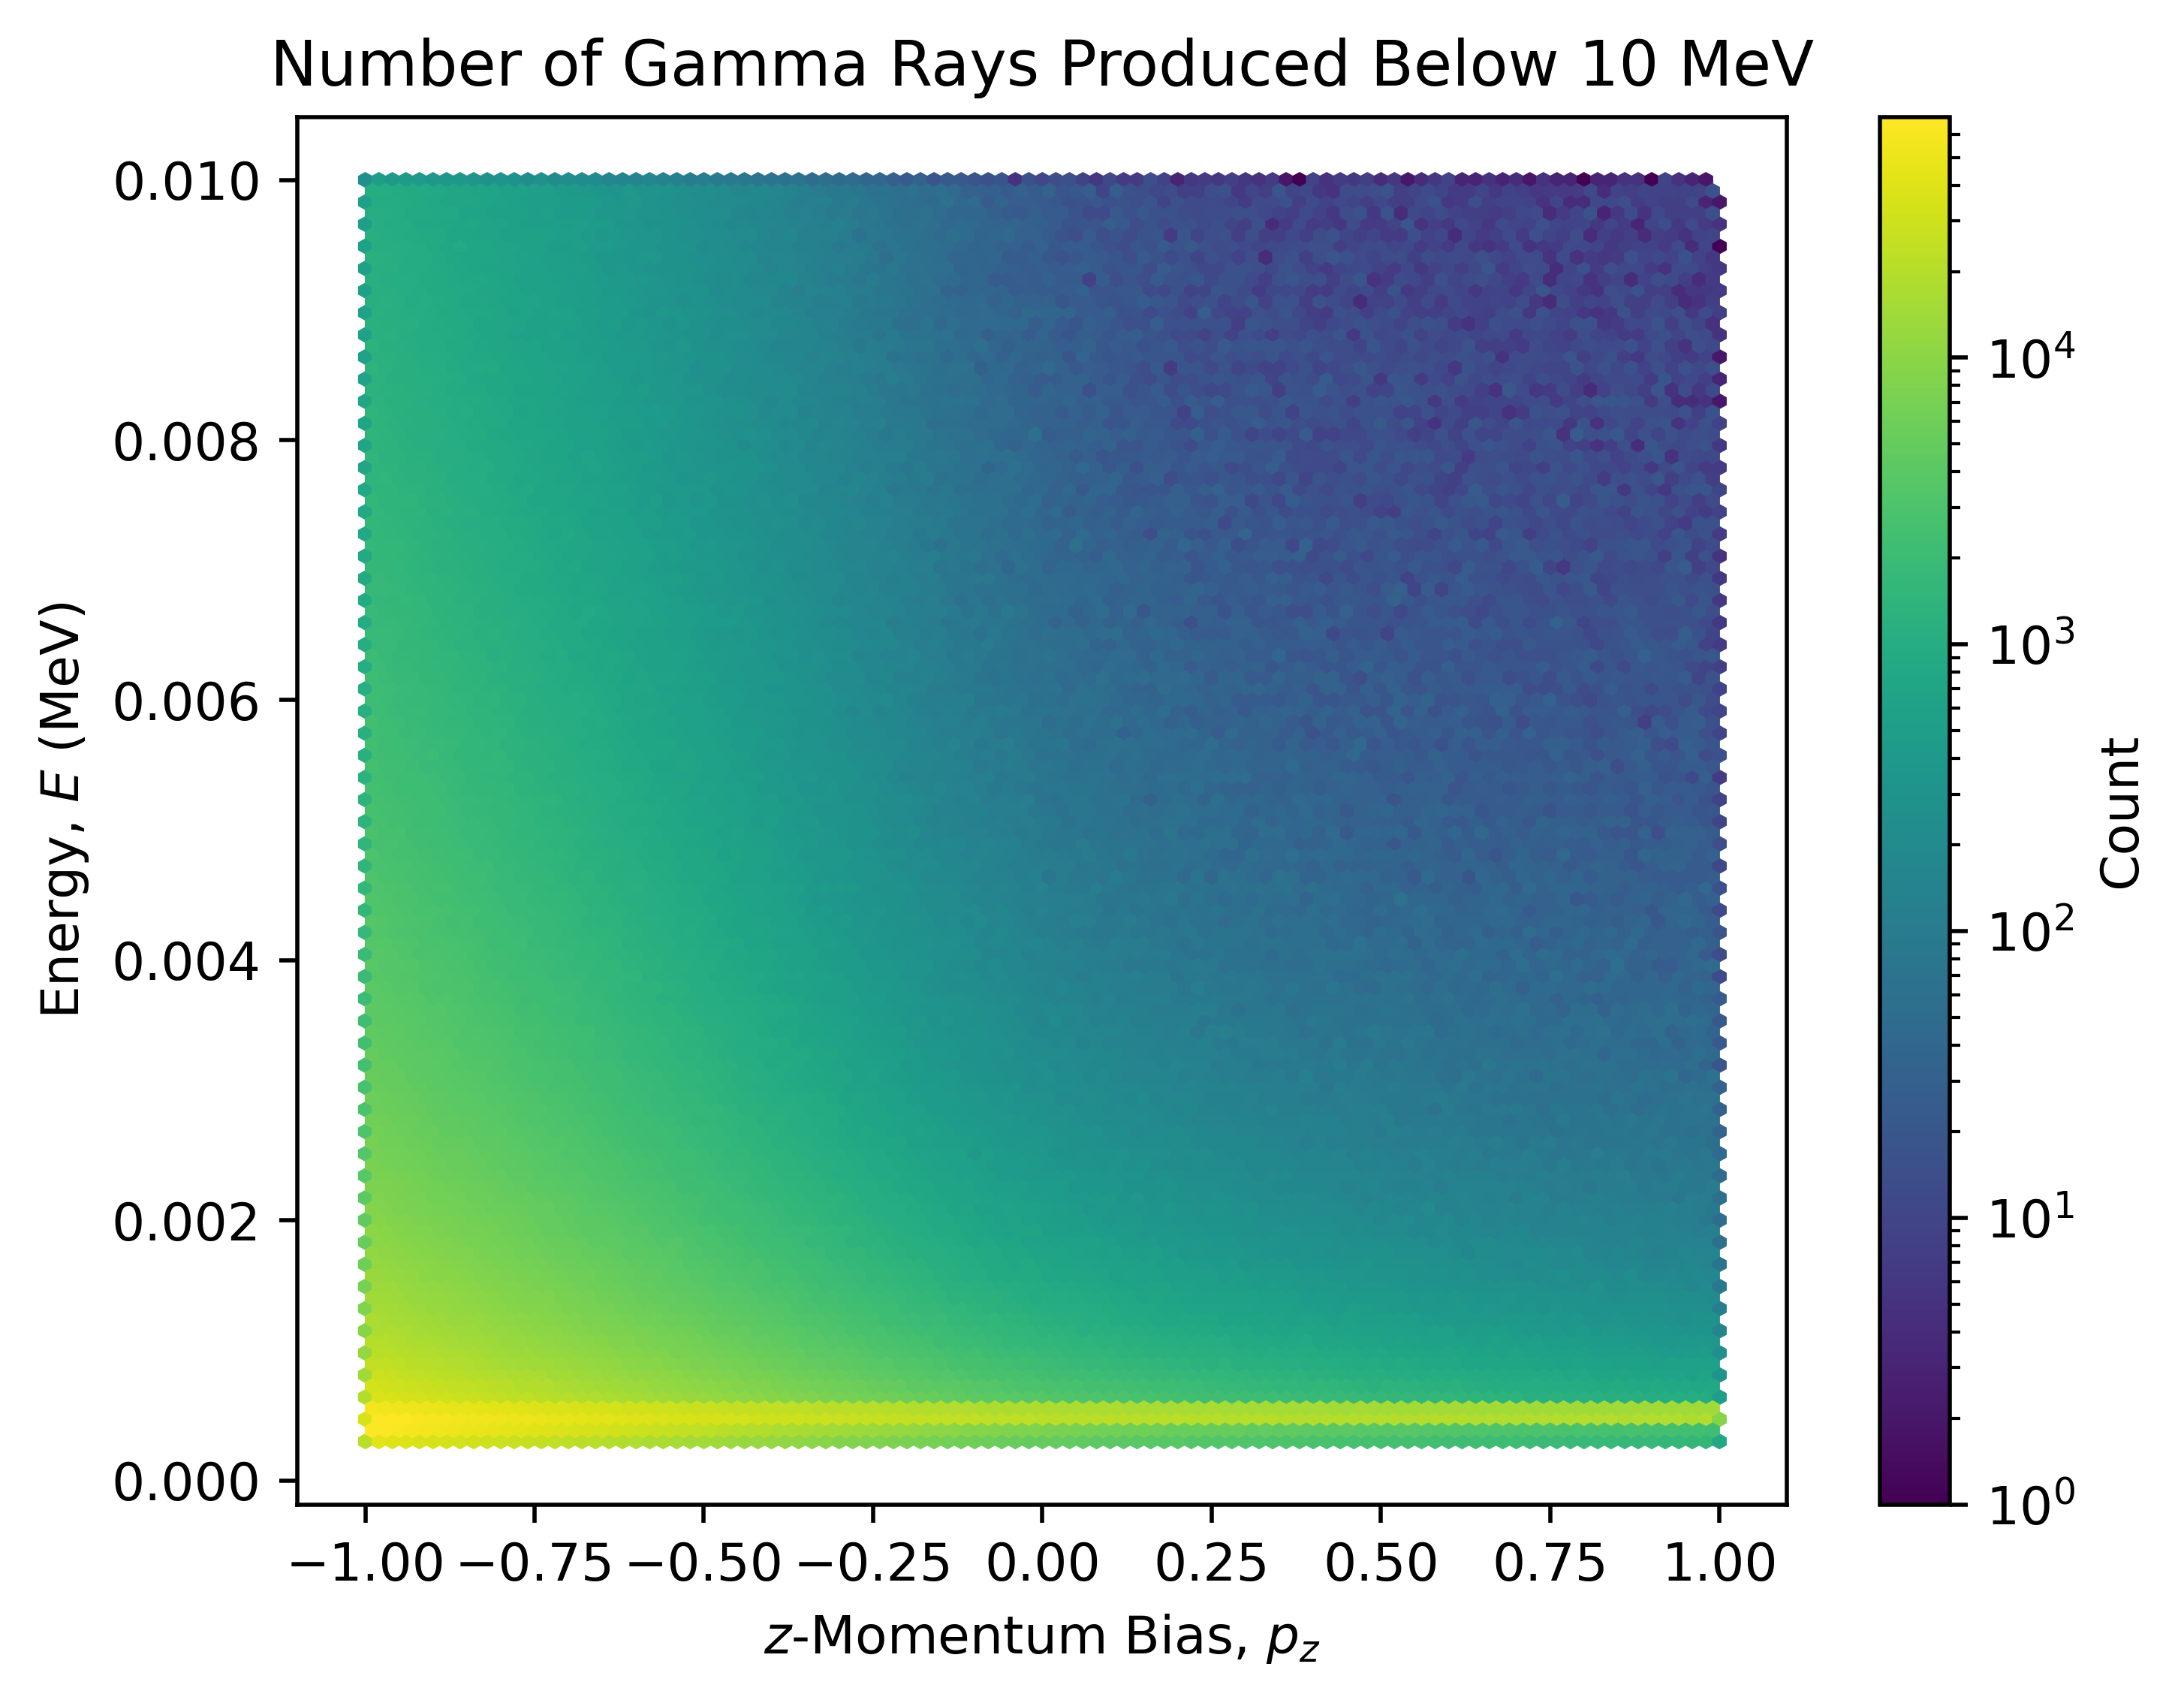

In [18]:
mask = df["E"].between(0, 10) & anisotropic
plt.hexbin(df[mask]["p_z"], df[mask]["E"] / 1e3, linewidths=0.2, norm=LogNorm())
plt.colorbar(label="Count")
plt.xlabel("$z$-Momentum Bias, $p_z$")
plt.ylabel("Energy, $E$ (MeV)")
plt.title("Number of Gamma Rays Produced Below 10 MeV")
plt.show()

In [19]:
def plot_process(name, plot_type: Literal["prop", "num"] = "prop", mask=None):
    plt.hexbin(
        (df if mask is None else df[mask])["p_z"],
        0.1 * (df if mask is None else df[mask])["z"],
        linewidths=0.2,
        C=include_processes([name], mask),
        reduce_C_function=np.mean if plot_type == "prop" else np.sum,
    )
    type_str = "Proportion" if plot_type == "prop" else "Number"
    plt.colorbar(label=type_str)
    plt.xlabel("$z$-Momentum Bias, $p_z$")
    plt.ylabel("Depth, $z$ (cm)")
    plt.title(f"{type_str} of Gamma Rays Produced\nby {name}")
    plt.show()

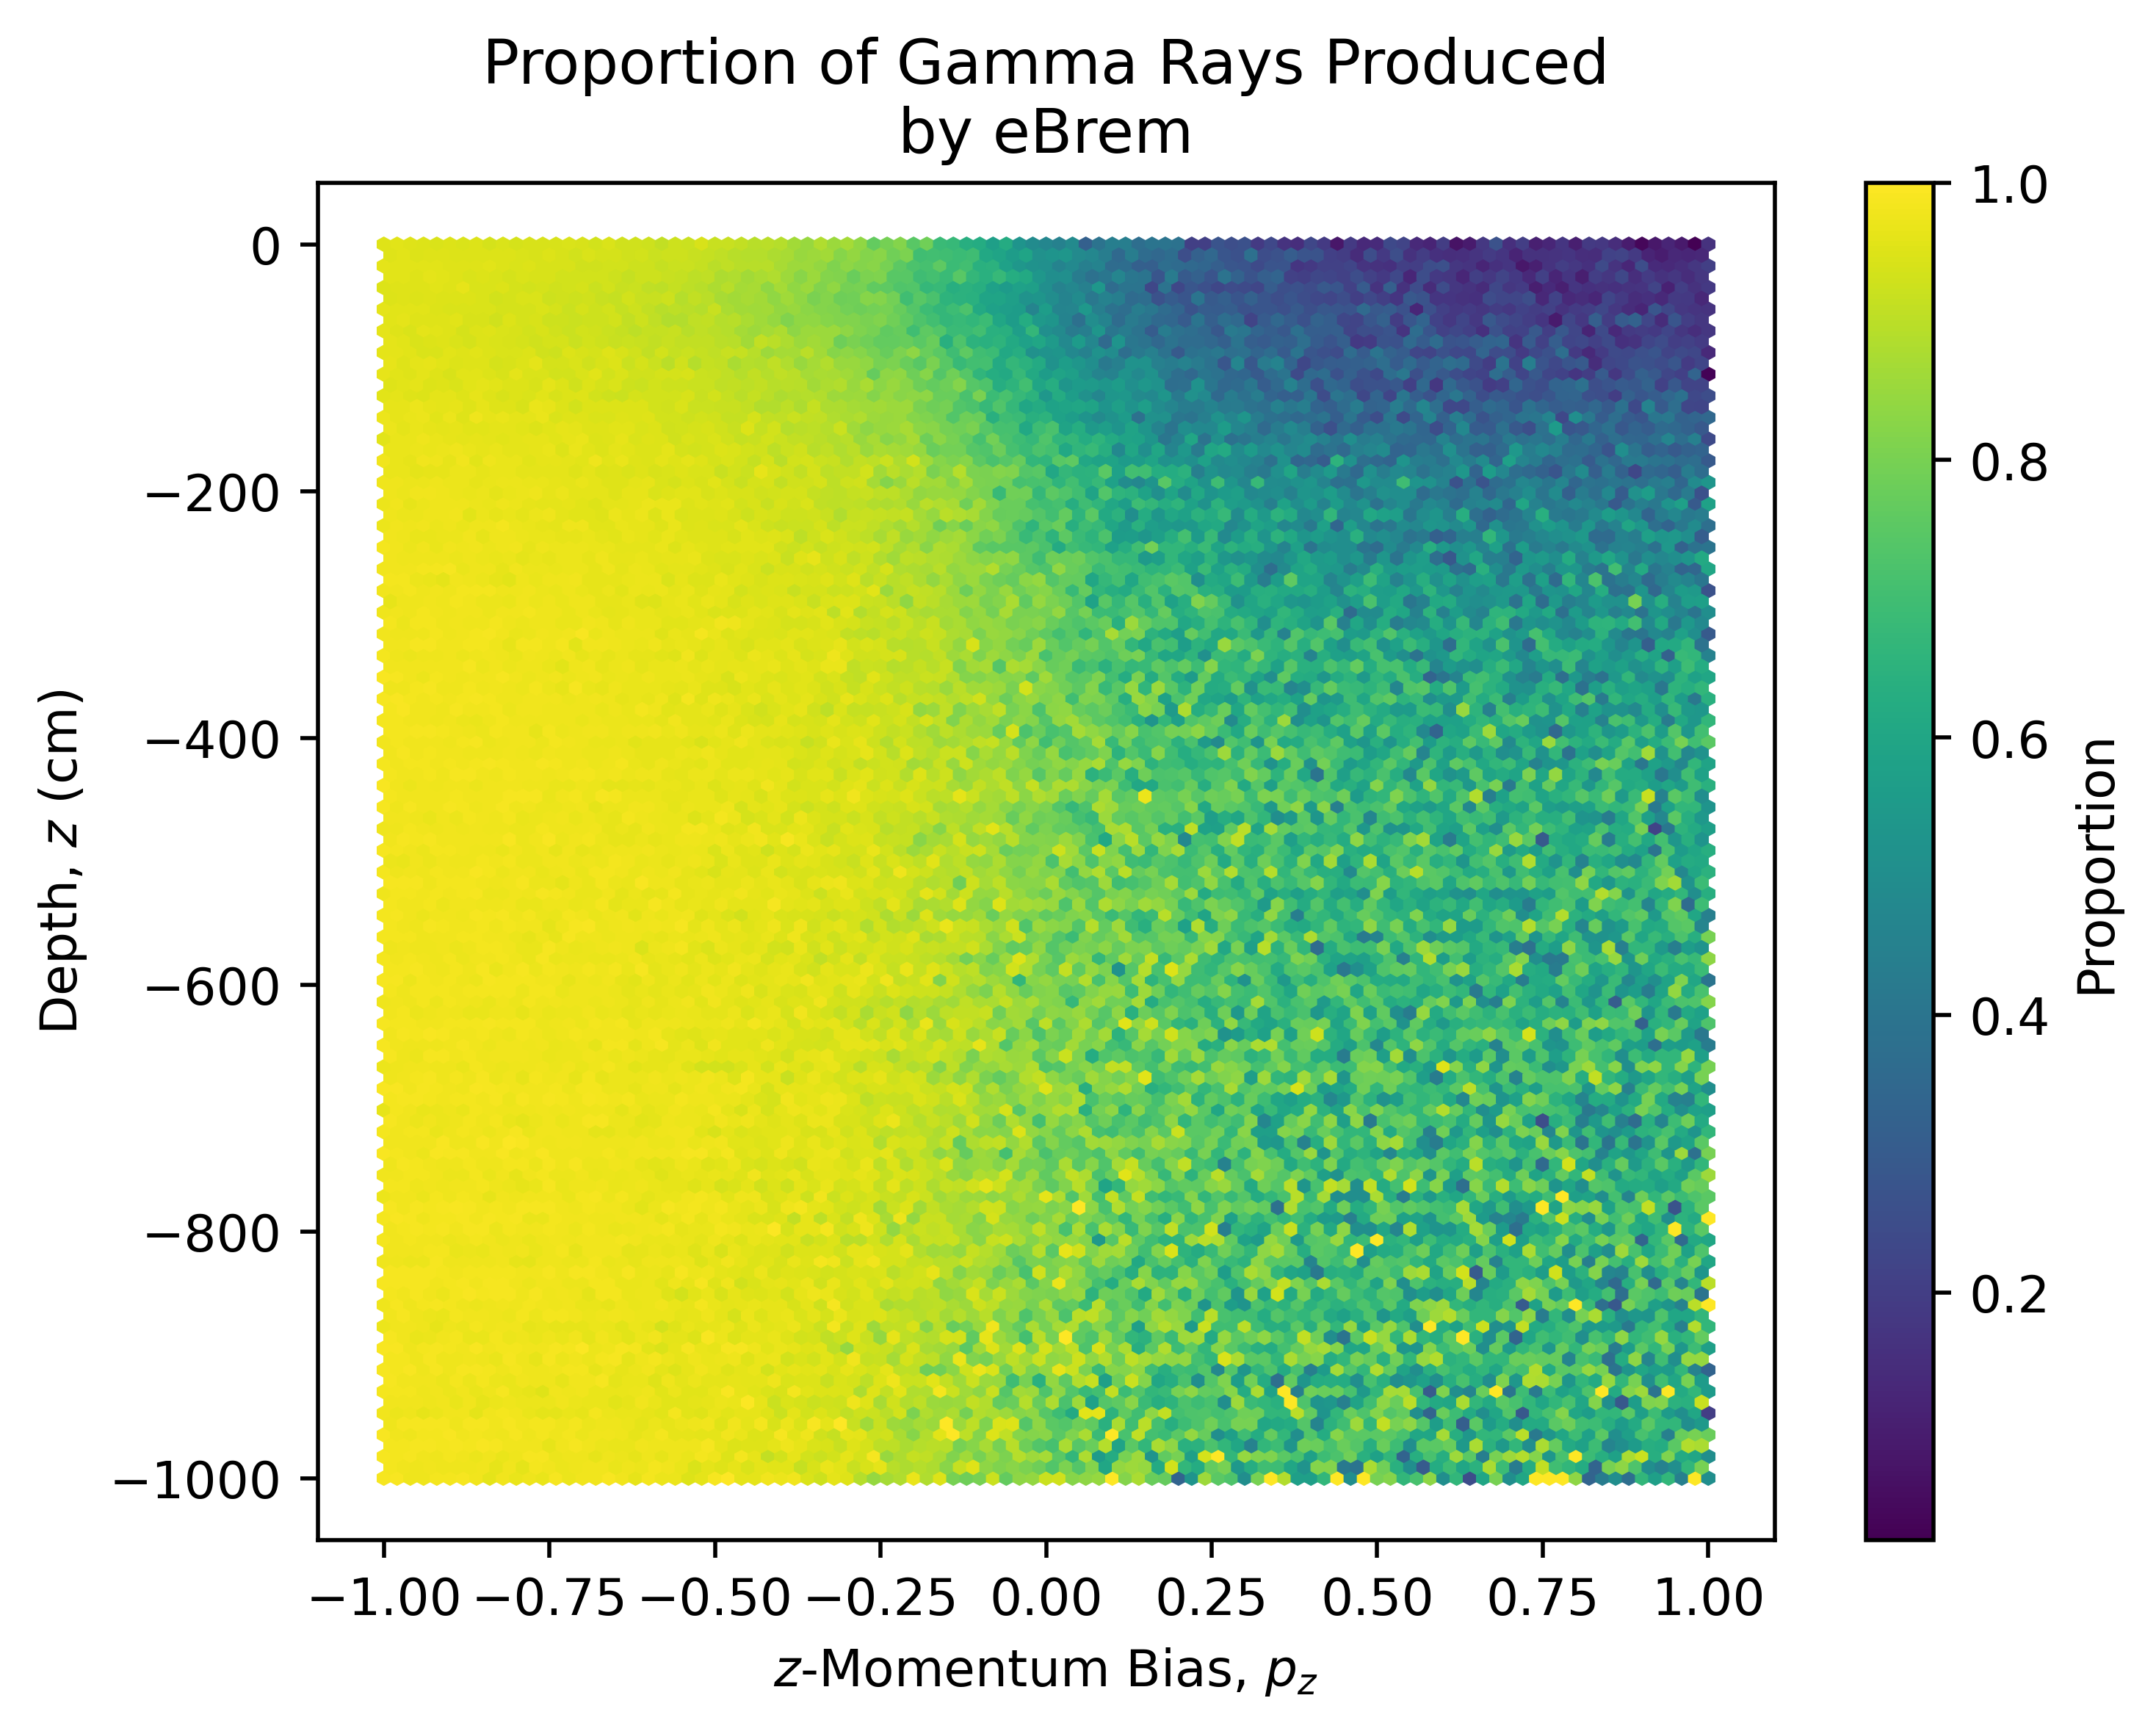

In [ ]:
plot_process(
    "eBrem",
    plot_type="prop",
    mask=df["E"].between(3, 1e10) & df["z"].between(-10000, 0),
)